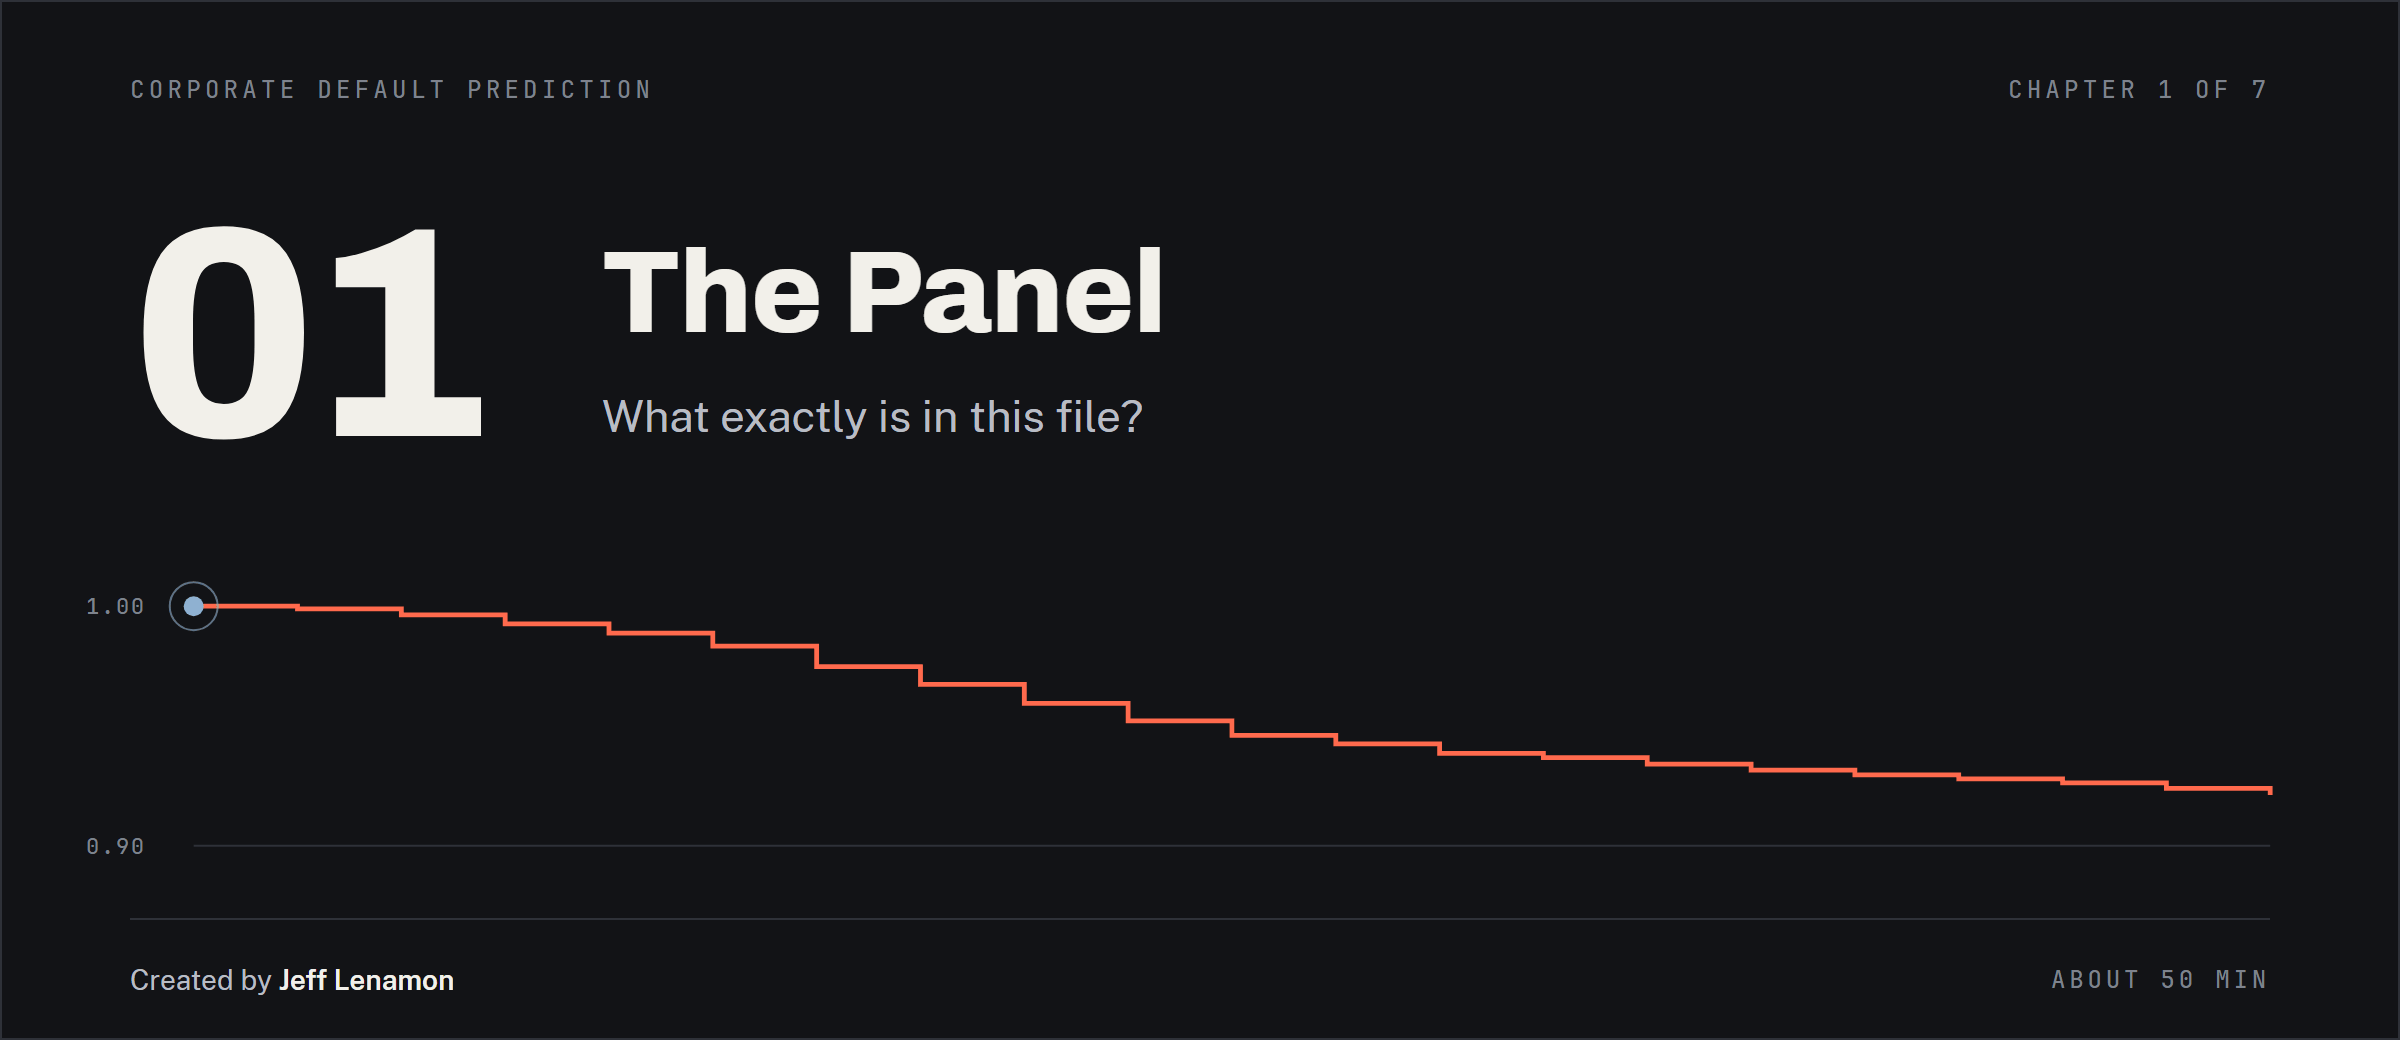

# Chapter 1: The Panel

What the dataset holds, who is in it, and what it cannot tell us, before any model is fitted.

> This casebook is educational content created in a personal capacity

> Nothing here is investment advice or a recommendation to buy or sell any security

> The data is a public research dataset with anonymised company names

## The Question

A colleague hands you a file of company accounts and a flag that says which companies went bankrupt.
The tempting next step is to fit a model.

The right next step is to find out what you are holding.
What exactly is in this file?

## What You Will Learn

By the end you can:

- say where the data comes from and what one row means;
- describe the panel: who is in it each year, who arrives late, and who leaves;
- profile the companies by size, losses, and industry;
- find the columns that repeat other columns;
- draw a signed, skewed number on a scale that shows it.

## What You Need

The data file, and nothing else.
`uv run python -m tools.get_data` fetches it and checks it.

This is the first chapter, so it reads nothing written by another one.

## Your Route

![Your route through Chapter 1: 1 Setting Up, 5 minutes; 2 Where the Data Comes From, 2 minutes; 3 The Flag and the Industry Codes, 3 minutes; 4 The Shape of the Panel, 6 minutes; 5 Late Arrivals and Gaps, 5 minutes; 6 Who These Companies Are, 6 minutes; 7 Do the Numbers Add Up, 5 minutes; 8 Signed Numbers Need a Signed Scale, 7 minutes; 9 What the File Cannot Tell Us, 1 minute.](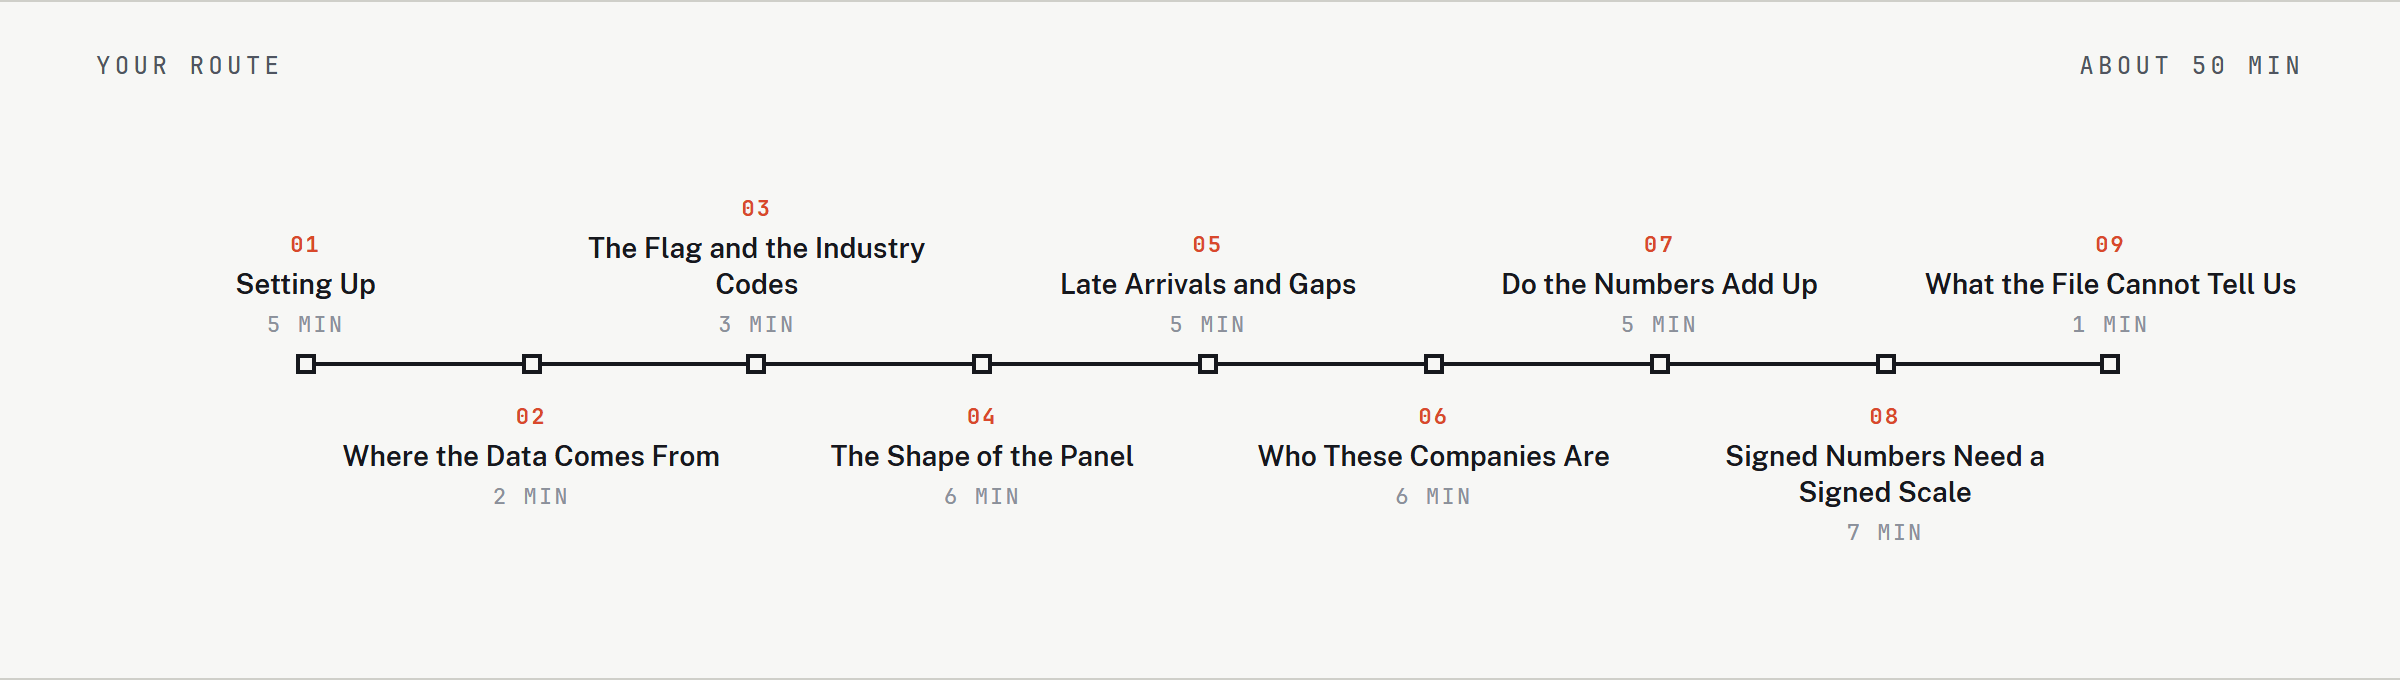)

**Time.** About 42 minutes to read and run, then about 9 for Your Turn.

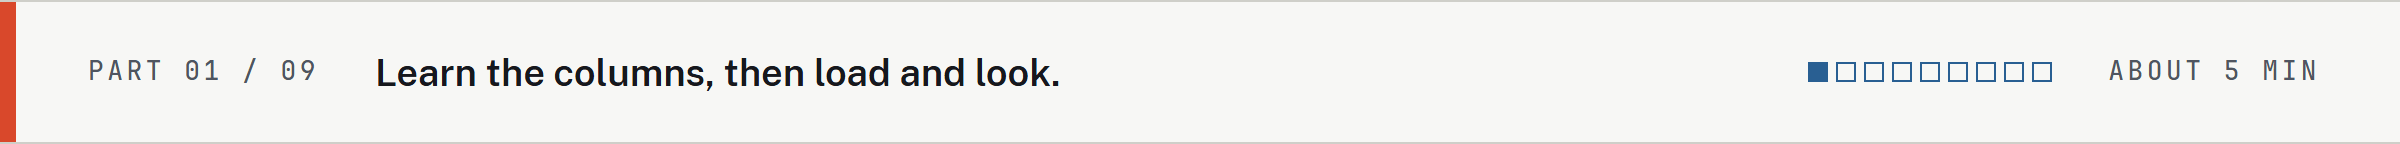

# Setting Up

Make sure the Jupyter kernel `corp-default` is selected before you run a cell.
If it is not in the list, or an import fails, the [Quick Start](../README.md#quick-start) shows how to register it and refresh the list.

## The Data Dictionary

Each row of the file is a **firm-year**: one company's annual accounts for one fiscal year.

The file names its accounting columns `X1` to `X18`.
The library gives them the names in the second column.

| Column | Name here | What it is |
| --- | --- | --- |
| `X1` | `current_assets` | Assets expected to turn into cash within a year |
| `X2` | `cogs` | Cost of goods sold |
| `X3` | `depreciation_amort` | Depreciation and amortization |
| `X4` | `ebitda` | Earnings before interest, taxes, depreciation, and amortization |
| `X5` | `inventory` | Inventory |
| `X6` | `net_income` | Net income, the bottom line |
| `X7` | `total_receivables` | Money owed to the company by its customers |
| `X8` | `market_cap` | Market value of the company's equity |
| `X9` | `net_sales` | Sales, net of returns and discounts |
| `X10` | `total_assets` | Total assets |
| `X11` | `total_lt_debt` | Long-term debt |
| `X12` | `ebit` | Earnings before interest and taxes |
| `X13` | `gross_profit` | Gross profit |
| `X14` | `total_current_liabilities` | Liabilities due within a year |
| `X15` | `retained_earnings` | Profits kept in the business since it began |
| `X16` | `total_revenue` | Total revenue |
| `X17` | `total_liabilities` | Total liabilities |
| `X18` | `total_operating_expenses` | Total operating expenses |

The other columns say which row this is.

| Column | What it is |
| --- | --- |
| `company_name` | The company's code, such as `C_1`, in place of its name |
| `year` | The fiscal year of the accounts |
| `status_label` | `alive` or `failed` |

A second file adds each company's industry.

| Column | What it is |
| --- | --- |
| `division` | The **SIC division**, a letter from A to J |
| `major_group` | The **major group**, a two-digit code inside the division |

Q. What does the chapter need before it can look at the file?

In [1]:
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, MaxNLocator, PercentFormatter

from corp_default import store, viz
from corp_default.data import (
    COLUMN_MAP,
    DATA_PATH,
    INDUSTRY_PATH,
    RAW_ITEMS,
    load_industry,
    load_raw,
    require_file,
)
from corp_default.labels import event_table

store.open_chapter(1)
viz.use_house_style()
SOURCE = "Lombardo et al. (2022), Kaggle copy"

raw = load_raw()
industry = load_industry()

**Reading.** The panel is in memory under the names in the dictionary, and the house style is set for every chart.
`store.put` carries a number from a cell into the text, so no number in this chapter is typed by hand.

Q. What does the table look like?

In [2]:
raw.head()

,company_name,status_label,year,current_assets,cogs,depreciation_amort,ebitda,inventory,net_income,total_receivables,market_cap,net_sales,total_assets,total_lt_debt,ebit,gross_profit,total_current_liabilities,retained_earnings,total_liabilities,total_operating_expenses
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,372.7519,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,377.1180,874.255,701.854,179.987,45.790,160.444,125.392,204.065,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,364.5928,638.721,710.199,217.699,4.711,112.244,150.464,139.603,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,143.3295,606.337,686.621,164.658,3.573,109.590,203.575,124.106,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,308.9071,651.958,709.292,248.666,20.811,128.656,131.261,131.884,407.608,604.467


**Reading.** Each row is one company in one year.
The first columns say which company, what its flag is, and which year, and the rest are that year's accounts.

Q. How large is the table, and what does each column hold?

In [3]:
store.put("columns", raw.shape[1])
store.put("raw_items", len(RAW_ITEMS))

print(raw.shape)
raw.info()

(78682, 20)
<class 'pandas.DataFrame'>
RangeIndex: 78682 entries, 0 to 78681
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   company_name               78682 non-null  str    
 1   status_label               78682 non-null  str    
 2   year                       78682 non-null  int64  
 3   current_assets             78682 non-null  float64
 4   cogs                       78682 non-null  float64
 5   depreciation_amort         78682 non-null  float64
 6   ebitda                     78682 non-null  float64
 7   inventory                  78682 non-null  float64
 8   net_income                 78682 non-null  float64
 9   total_receivables          78682 non-null  float64
 10  market_cap                 78682 non-null  float64
 11  net_sales                  78682 non-null  float64
 12  total_assets               78682 non-null  float64
 13  total_lt_debt              78682 non-null  fl

**Reading.** The table has 78,682 rows and 20 columns, and no column is missing a value.
The company code and the flag are text, the year is a whole number, and the other 17 columns are decimals.

Q. What values does each column take?

In [4]:
summary = raw.describe().T
# The reading below says every account's mean is above its median. Checked here.
assert (summary.loc[RAW_ITEMS, "mean"] > summary.loc[RAW_ITEMS, "50%"]).all()
store.put(
    "assets_mean_to_median",
    summary.loc["total_assets", "mean"] / summary.loc["total_assets", "50%"],
)

summary.round(1)

,count,mean,std,min,25%,50%,75%,max
year,78682.0,2007.5,5.7,1999.0,2002.0,2007.0,2012.0,2018.0
current_assets,78682.0,880.4,3928.6,-7.8,18.9,100.4,431.5,169662.0
cogs,78682.0,1594.5,8930.5,-366.6,17.0,103.7,634.5,374623.0
depreciation_amort,78682.0,121.2,652.4,0.0,1.2,7.9,48.0,28430.0
ebitda,78682.0,376.8,2012.0,-21913.0,-0.8,15.0,139.7,81730.0
inventory,78682.0,201.6,1060.8,0.0,0.0,7.0,74.7,62567.0
net_income,78682.0,129.4,1265.5,-98696.0,-7.4,1.6,40.1,104821.0
total_receivables,78682.0,286.8,1336.0,-0.0,3.3,22.8,131.6,65812.0
market_cap,78682.0,3414.4,18414.1,0.0,35.0,227.5,1244.9,1073390.5
net_sales,78682.0,2364.0,11950.1,-1965.0,27.5,186.6,1046.4,511729.0


**Reading.** In every account the mean is above the median, the `50%` column: for total assets it is 13 times as large.
Several minimums are negative, because a line of earnings can be a loss.

A few very large companies and a good many losses shape every chart in this chapter.

**Next, where the file comes from.**

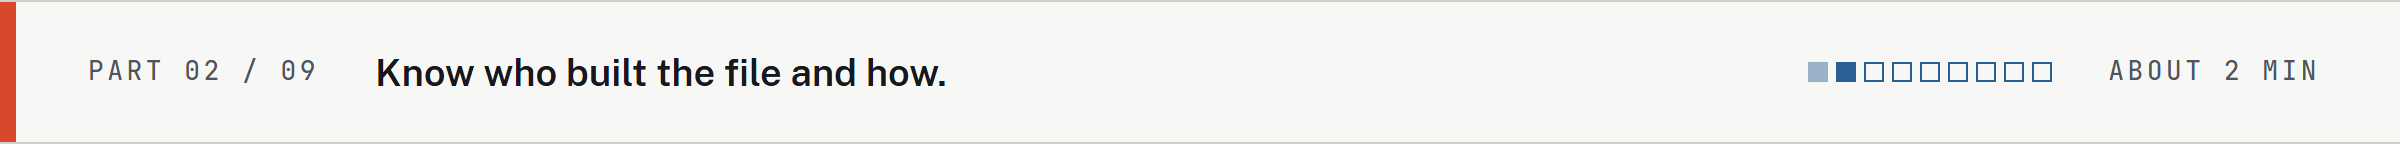

# Where the Data Comes From

The dataset was published with [Lombardo et al. (2022)](https://doi.org/10.3390/fi14080244), a paper that pairs it with a set of benchmark models.
It covers companies listed on the New York Stock Exchange and NASDAQ.

A company counts as bankrupt when it files under Chapter 11 or Chapter 7 of the Bankruptcy Code.

The copy used here is the one on [Kaggle](https://www.kaggle.com/datasets/utkarshx27/american-companies-bankruptcy-prediction-dataset).
`tools.get_data` downloads it and refuses a file whose checksum differs from the one on record.

A set of firm-years that follows the same companies through time is a **panel**.

Neither the paper nor the Kaggle page states the units of the accounts.
This casebook works in ratios wherever it can, and it never quotes a dollar amount.

Q. How big is the panel, and does it match the paper?

In [5]:
PAPER = {"firm-years": 78_682, "companies": 8_262}  # as the paper states them; see SOURCES.md

firm_years = len(raw)
companies = raw["company_name"].nunique()
first_year, last_year = int(raw["year"].min()), int(raw["year"].max())

store.put("firm_years", firm_years)
store.put("companies", companies)
store.put("first_year", first_year)
store.put("last_year", last_year)
store.put("n_years", last_year - first_year + 1)
store.put("paper_companies", PAPER["companies"])
store.put("extra_companies", companies - PAPER["companies"])

counts = pd.DataFrame({"file": {"firm-years": firm_years, "companies": companies}, "paper": PAPER})
counts.assign(difference=counts["file"] - counts["paper"])

,file,paper,difference
firm-years,78682,78682,0
companies,8971,8262,709


**Reading.** The file holds 78,682 firm-years from 8,971 companies, for fiscal years 1999 to 2018.
The firm-year count matches the paper.

The company count does not: the paper states 8,262, and the file holds 709 more.
No subset of the file that we tried gives the paper's number, so the difference stays open.

**Check.** The companies have codes in place of names. What does that rule out?

<details>
<summary>Show the answer</summary>

Anything from outside the file.
No rating, price history, news, or filing date can be joined to a company.

Every feature in this casebook has to be built from the columns of this one file.

</details>

**Next, the flag and the industry codes.**

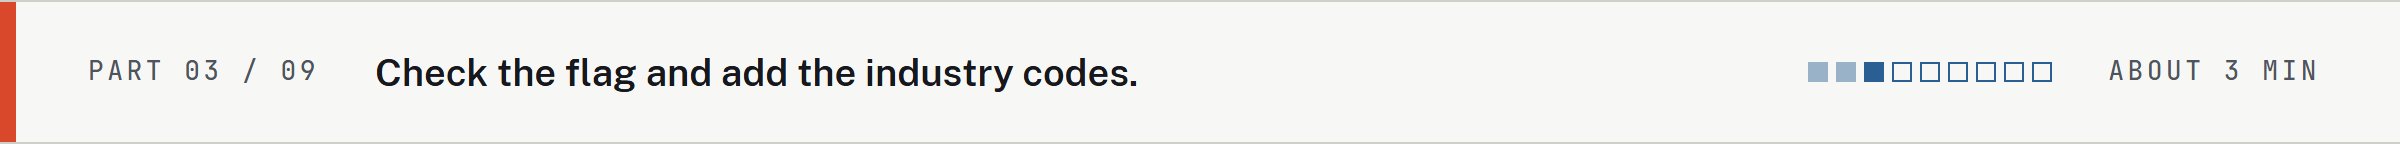

# The Flag and the Industry Codes

The dictionary gives `status_label` one line.
Everything this casebook predicts is built from it, so it earns a closer look.

Q. Does `status_label` describe a year or a company?

In [6]:
labels_per_company = raw.groupby("company_name")["status_label"].nunique()
failed_rows = raw["status_label"] == "failed"

store.put("failed_companies", raw.loc[failed_rows, "company_name"].nunique())
store.put("failed_rows", int(failed_rows.sum()))

print("most labels any one company carries:", labels_per_company.max())
raw["status_label"].value_counts()

most labels any one company carries: 1


status_label
alive     73462
failed     5220
Name: count, dtype: int64

**Reading.** No company carries more than one label, so the flag marks a company and says nothing about the year.
The 5,220 `failed` rows belong to 609 companies.

Chapter 2 turns the flag into an event with a date.

The Kaggle file has no industry.
A later copy of the dataset from the same authors adds industry codes for the same companies.

The codes come from the [Standard Industrial Classification](https://www.osha.gov/data/sic-manual), or SIC.
`tools.get_data` keeps the division and the major group from that copy and nothing else.

Q. How does the library load the two files?

Both loaders start with `require_file`, which stops with the command that fetches the data when a file is missing.

In [7]:
# taught: corp_default.data.load_raw
def load_raw(path: Path = DATA_PATH) -> pd.DataFrame:
    """The panel with readable column names; total_revenue is dropped because it equals net_sales."""
    require_file(path)
    frame = pd.read_csv(path).rename(columns=COLUMN_MAP)
    return frame.drop(columns=["total_revenue"])

In [8]:
# taught: corp_default.data.load_industry
def load_industry(path: Path = INDUSTRY_PATH, data_path: Path = DATA_PATH) -> pd.DataFrame:
    """SIC division and major group per company, refused unless it covers the panel exactly."""
    require_file(path)
    require_file(data_path)
    codes = pd.read_csv(path).drop_duplicates()
    repeated = codes.loc[codes["company_name"].duplicated(), "company_name"]
    if not repeated.empty:
        raise ValueError(f"companies with more than one industry code: {sorted(set(repeated))[:5]}")
    companies = set(pd.read_csv(data_path, usecols=["company_name"])["company_name"])
    unmatched = companies.symmetric_difference(codes["company_name"])
    if unmatched:
        raise ValueError(
            f"{len(unmatched)} companies are in only one of {path.name} and {data_path.name}, "
            f"for example {sorted(unmatched)[:5]}"
        )
    return codes.set_index("company_name")

**Reading.** `load_raw` renames the columns and drops `total_revenue`, which a later part shows to be a copy of `net_sales`.
`load_industry` refuses the codes unless every company in the panel has exactly one.

Q. Which industries are in the panel?

In [9]:
# The functions typed above give the same frames as the library's own.
assert load_raw().equals(raw) and load_industry().equals(industry)

# The divisions of the SIC Manual.
DIVISIONS = {
    "A": "Agriculture, Forestry, and Fishing",
    "B": "Mining",
    "C": "Construction",
    "D": "Manufacturing",
    "E": "Transportation, Communications, Electric, Gas, and Sanitary Services",
    "F": "Wholesale Trade",
    "G": "Retail Trade",
    "H": "Finance, Insurance, and Real Estate",
    "I": "Services",
    "J": "Public Administration",
}

by_division = industry.groupby("division").agg(
    companies=("major_group", "size"), major_groups=("major_group", "nunique")
)
by_division.insert(0, "name", by_division.index.map(DIVISIONS))
by_division["share"] = (by_division["companies"] / by_division["companies"].sum()).round(3)

store.put("manufacturing_share", by_division.loc["D", "companies"] / len(industry))
store.put("services_share", by_division.loc["I", "companies"] / len(industry))
store.put("finance_share", by_division.loc["H", "companies"] / len(industry))
store.put("major_groups", industry["major_group"].nunique())

by_division

,name,companies,major_groups,share
division,,,,
A,"Agriculture, Forestry, and Fishing",47,5,0.005
B,Mining,510,4,0.057
C,Construction,70,3,0.008
D,Manufacturing,4100,20,0.457
E,"Transportation, Communications, Electric, Gas,...",784,9,0.087
F,Wholesale Trade,349,2,0.039
G,Retail Trade,613,8,0.068
H,"Finance, Insurance, and Real Estate",289,7,0.032
I,Services,2205,14,0.246


**Reading.** Manufacturing is 46% of the companies and services another 25%.
Finance, insurance, and real estate come to only 3%, and the divisions break into 73 major groups.

**Next, the panel through time.**

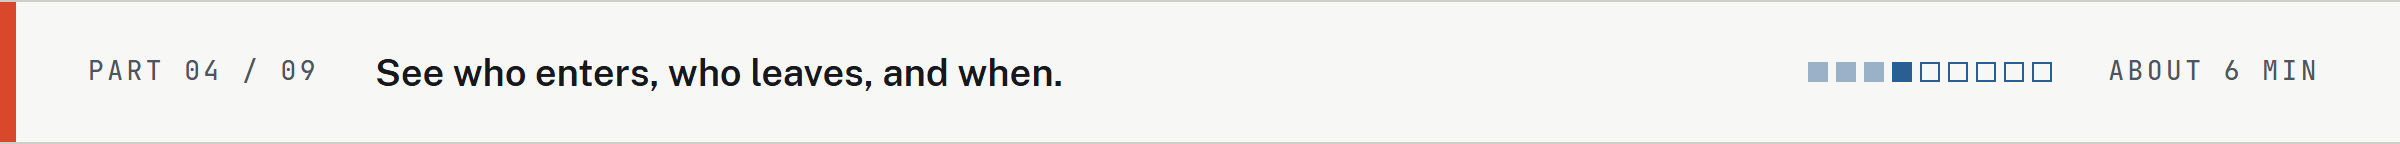

# The Shape of the Panel

A panel is not a fixed list of companies.
Companies join it and leave it, and the mix in the last year is not the mix in the first.

**Predict 1.** The file starts with 5,308 companies in 1999.
How many are filing in 2018?

Q. How many companies file accounts each year?

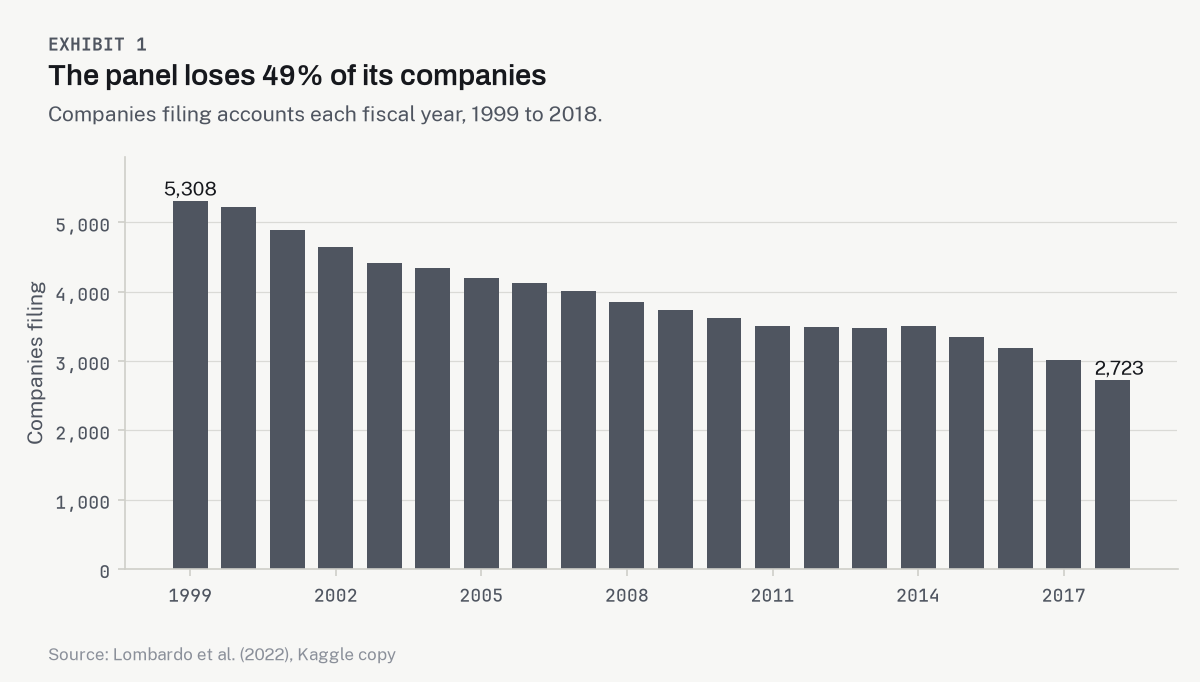

In [10]:
filing = raw.groupby("year")["company_name"].nunique()

store.put("companies_first_year", filing.loc[first_year])
store.put("companies_last_year", filing.loc[last_year])
store.put("shrink", 1 - filing.loc[last_year] / filing.loc[first_year])

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.2))
ax.bar(filing.index, filing, width=0.72, color=viz.SLATE)
ax.text(first_year, filing.loc[first_year] + 80, f"{filing.loc[first_year]:,}", ha="center", size=9)
ax.text(last_year - 0.36, filing.loc[last_year] + 80, f"{filing.loc[last_year]:,}", size=9)
ax.set_xticks(range(first_year, last_year + 1, 3))
ax.set_ylim(0, filing.max() * 1.12)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.grid(axis="x", visible=False)
ax.set_ylabel("Companies filing")
viz.exhibit(
    fig,
    f"The panel loses {1 - filing.loc[last_year] / filing.loc[first_year]:.0%} of its companies",
    f"Companies filing accounts each fiscal year, {first_year} to {last_year}.",
    SOURCE,
)

**Reading.** Exhibit 1 falls in almost every year.
By 2018 there are 2,723 companies, 49% fewer than at the start.

A falling count means more companies leave than join.

Q. Who joins, who leaves, and how do they leave?

`event_table` gives one row per company: its first and last year in the file, and how its history ends.
A company is `failed` if it carries the flag, `reporting` if it is still filing in the last year, and `left` otherwise.

Chapter 2 builds that table step by step.

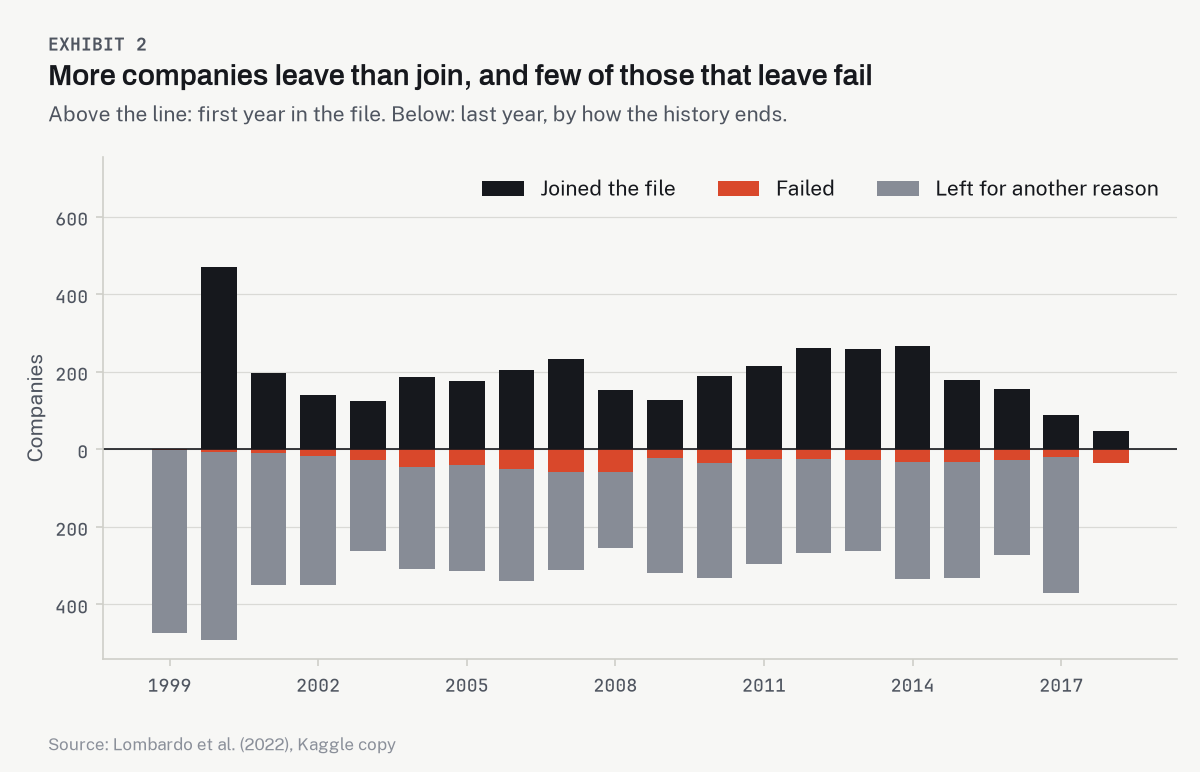

In [11]:
events = event_table(raw)
entries = events.loc[events["entry_year"] > first_year, "entry_year"].value_counts().sort_index()
exits = (
    events.loc[events["event"] != "reporting"]
    .groupby(["exit_year", "event"])
    .size()
    .unstack(fill_value=0)
)

store.put("entered_later", int(entries.sum()))
store.put("left", int(exits["left"].sum()))
store.put("failed_share_of_exits", exits["failed"].sum() / exits.to_numpy().sum())
store.put("reporting", int((events["event"] == "reporting").sum()))

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.8))
ax.bar(entries.index, entries, width=0.72, color=viz.INK, label="Joined the file")
ax.bar(exits.index, -exits["failed"], width=0.72, color=viz.FAILED, label="Failed")
ax.bar(
    exits.index,
    -exits["left"],
    bottom=-exits["failed"],
    width=0.72,
    color=viz.CENSORED,
    label="Left for another reason",
)
ax.axhline(0, color=viz.INK, linewidth=0.8)
ax.set_xticks(range(first_year, last_year + 1, 3))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{abs(value):,.0f}"))
ax.grid(axis="x", visible=False)
ax.set_ylabel("Companies")
ax.set_ylim(top=entries.max() * 1.6)
ax.legend(loc="upper right", ncols=3)
viz.exhibit(
    fig,
    "More companies leave than join, and few of those that leave fail",
    "Above the line: first year in the file. Below: last year, by how the history ends.",
    SOURCE,
)

**Reading.** Exhibit 2 counts 3,663 companies that join after 1999 and 5,675 that leave without failing.
Failure is the rare way out: 10% of all exits.

The file does not say why the others leave.
A merger, a buyout, and a delisting all look the same here.

Only 2,687 companies are still filing in 2018.

Q. What does one company's history look like?

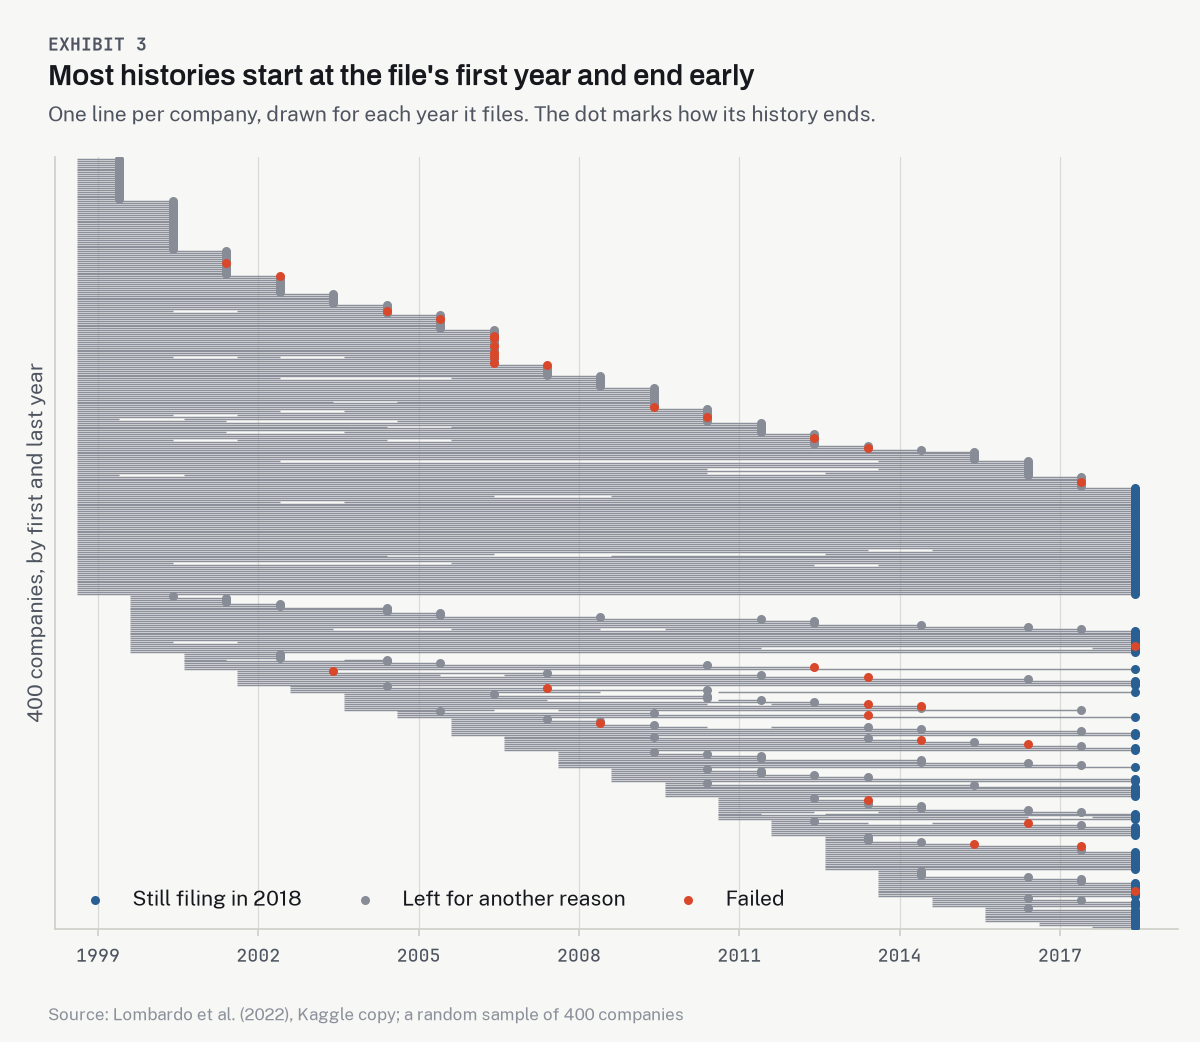

In [12]:
sample = (
    events.sample(400, random_state=42)
    .sort_values(["entry_year", "exit_year"])
    .reset_index(drop=True)
)
rows = raw.merge(sample[["company_name"]].assign(row=sample.index), on="company_name")
rows = rows.sort_values(["row", "year"])
# A run is a stretch of consecutive years; a missing year starts a new run.
starts_run = rows.groupby("row")["year"].diff().ne(1)
runs = rows.assign(run=starts_run.cumsum()).groupby(["row", "run"])["year"].agg(["min", "max"])
runs = runs.reset_index()

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 5.6))
ax.hlines(runs["row"], runs["min"] - 0.4, runs["max"] + 0.4, color=viz.MIST, linewidth=0.7)
endings = [
    ("reporting", viz.SURVIVED, f"Still filing in {last_year}"),
    ("left", viz.CENSORED, "Left for another reason"),
    ("failed", viz.FAILED, "Failed"),
]
for event, color, label in endings:
    ends = sample.loc[sample["event"] == event]
    ax.scatter(ends["exit_year"] + 0.4, ends.index, s=11, color=color, label=label, zorder=3)
ax.set_xticks(range(first_year, last_year + 1, 3))
ax.set_xlim(first_year - 0.8, last_year + 1.2)
ax.set_ylim(len(sample), -1)
ax.set_yticks([])
ax.grid(axis="y", visible=False)
ax.set_ylabel(f"{len(sample)} companies, by first and last year")
ax.legend(loc="lower left", ncols=3)
viz.exhibit(
    fig,
    "Most histories start at the file's first year and end early",
    "One line per company, drawn for each year it files. The dot marks how its history ends.",
    f"{SOURCE}; a random sample of {len(sample)} companies",
    save_as="ch1",
)

**Reading.** Most lines in Exhibit 3 begin at the left edge, in 1999, and most end with a grey dot long before the right edge.
A few lines have a break in them, where a company skips a year or more.

**Next, those late arrivals, short histories, and breaks, measured.**

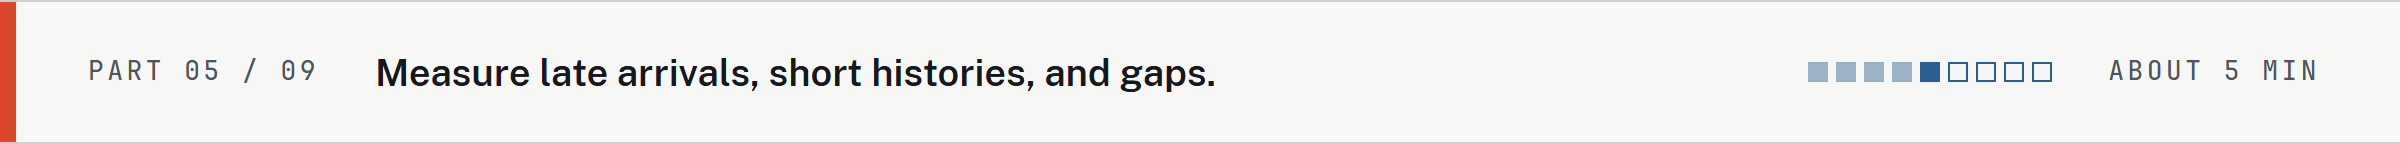

# Late Arrivals and Gaps

A company first seen in 1999 did not start in 1999.
The file starts there.

Its earlier years are cut off, and this is called **left truncation**.

**Predict 2.** The file spans 20 years.
What share of the companies file in all of them?

Q. How long is each company's history, and is it complete?

In [13]:
# taught: corp_default.data.panel_spans
def panel_spans(frame: pd.DataFrame) -> pd.DataFrame:
    """One row per company: first and last year, years present, missing years inside the span."""
    grouped = frame.groupby("company_name")
    spans = grouped["year"].agg(first_year="min", last_year="max", n_years="nunique")
    spans["n_gap_years"] = spans["last_year"] - spans["first_year"] + 1 - spans["n_years"]
    spans["failed"] = grouped["status_label"].agg(lambda s: bool((s == "failed").any()))
    return spans

In [14]:
spans = panel_spans(raw)
truncated = spans["first_year"] == first_year
complete = spans["n_years"] == last_year - first_year + 1
with_gaps = spans["n_gap_years"] > 0

store.put("first_seen", int(truncated.sum()))
store.put("first_seen_share", truncated.mean())
store.put("median_history", spans["n_years"].median())
store.put("one_year", int((spans["n_years"] == 1).sum()))
store.put("complete", int(complete.sum()))
store.put("complete_share", complete.mean())
store.put("gap_companies", int(with_gaps.sum()))
store.put("gap_share", with_gaps.mean())
store.put("longest_gap", spans["n_gap_years"].max())

spans.drop(columns="failed").describe().loc[["min", "50%", "max"]].T.astype(int)

,min,50%,max
first_year,1999,1999,2018
last_year,1999,2012,2018
n_years,1,7,20
n_gap_years,0,0,15


**Reading.** The file already holds 5,308 companies in 1999, 59% of all, so their earlier history is unseen.
The median company files for 7 years, and 755 file once.

Only 1,172 companies, 13%, are present in all 20 years.

Q. Do later arrivals last longer?

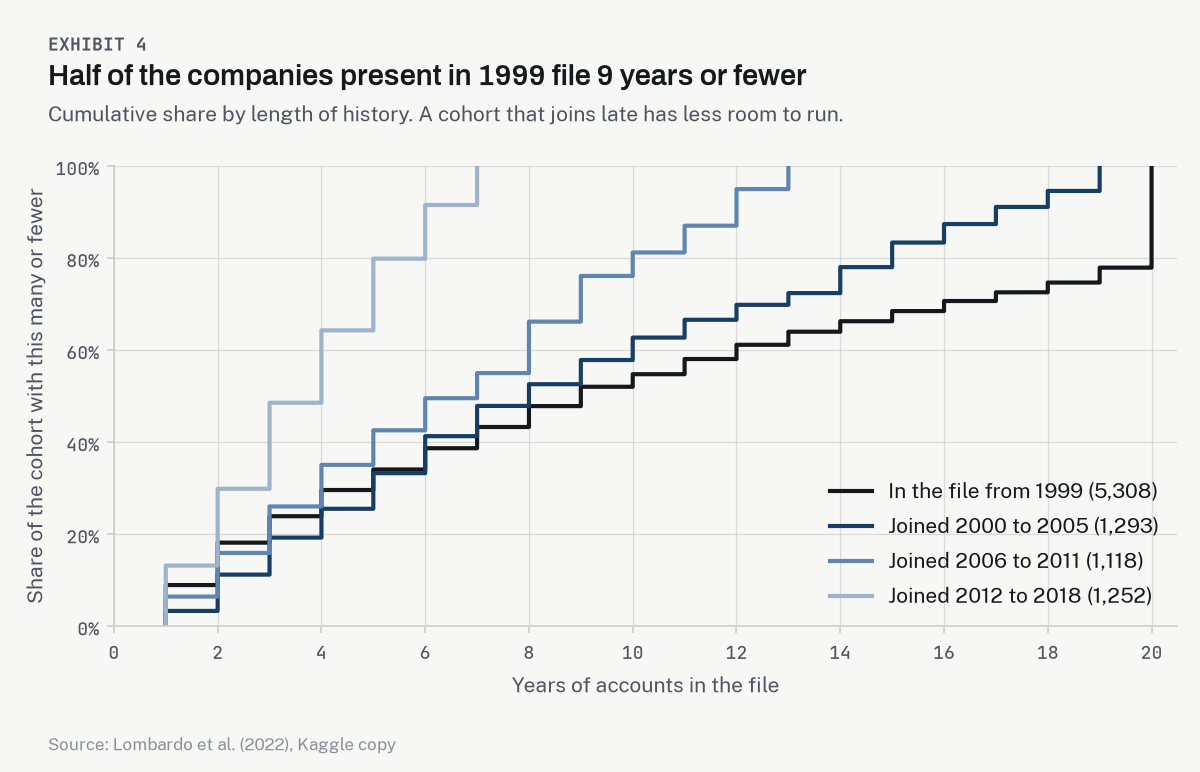

In [15]:
cohorts = [
    (f"In the file from {first_year}", spans["first_year"] == first_year, viz.INK),
    ("Joined 2000 to 2005", spans["first_year"].between(2000, 2005), "#173F66"),
    ("Joined 2006 to 2011", spans["first_year"].between(2006, 2011), "#5F86AE"),
    (f"Joined 2012 to {last_year}", spans["first_year"] >= 2012, "#9DB4CC"),
]

median_first = spans.loc[truncated, "n_years"].median()
store.put("median_first", median_first)

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.8))
for label, members, color in cohorts:
    ax.ecdf(spans.loc[members, "n_years"], color=color, label=f"{label} ({members.sum():,})")
ax.set_xticks(range(0, last_year - first_year + 2, 2))
ax.set_xlim(0, last_year - first_year + 1.5)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Years of accounts in the file")
ax.set_ylabel("Share of the cohort with this many or fewer")
ax.legend(loc="lower right")
viz.exhibit(
    fig,
    f"Half of the companies present in {first_year} file {median_first:.0f} years or fewer",
    "Cumulative share by length of history. A cohort that joins late has less room to run.",
    SOURCE,
)

**Reading.** Every curve in Exhibit 4 climbs fast: short histories are the rule, whenever a company joins.
Half of the companies present in 1999 file for 9 years or fewer.

The later cohorts stop early for a second reason: a company that joins late has only a few years to show before the file ends.
The jump at the right end of the black curve is the companies present throughout.

Q. How common are breaks inside a history?

In [16]:
gap_lengths = spans.loc[with_gaps, "n_gap_years"]
bands = pd.cut(gap_lengths, [0, 1, 2, 5, 20], labels=["1 year", "2 years", "3 to 5", "6 or more"])
bands.value_counts(sort=False).rename("companies").to_frame()

,companies
n_gap_years,
1 year,311
2 years,151
3 to 5,173
6 or more,75


**Reading.** A break of at least one year shows in 710 companies, 8% of all, and the longest is 15 years.

A break matters as soon as a feature compares this year with last year.
The row above this year's accounts may be from several years earlier, so Chapter 3 joins on the calendar year.

**Check.** A company is first seen in 1999 and leaves some years later. Can you say how long it survived from its listing?

<details>
<summary>Show the answer</summary>

No.
You can say only how long it was observed.

It was already listed when the file begins, and its earlier years are cut off.
A survival curve that treats the first year in the file as the first year of life is wrong for these companies, and Chapter 2 deals with it.

</details>

**Next, what kind of companies these are.**

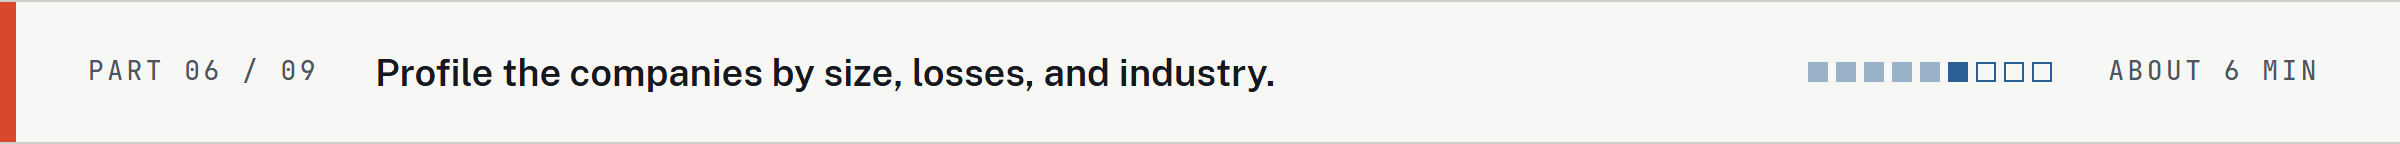

# Who These Companies Are

A default model learns the companies it is shown.
If they are unlike the companies you care about, its numbers do not carry over.

**Predict 3.** In a typical year, what share of these listed companies report a net loss?

Q. How large and how profitable is the typical company, year by year?

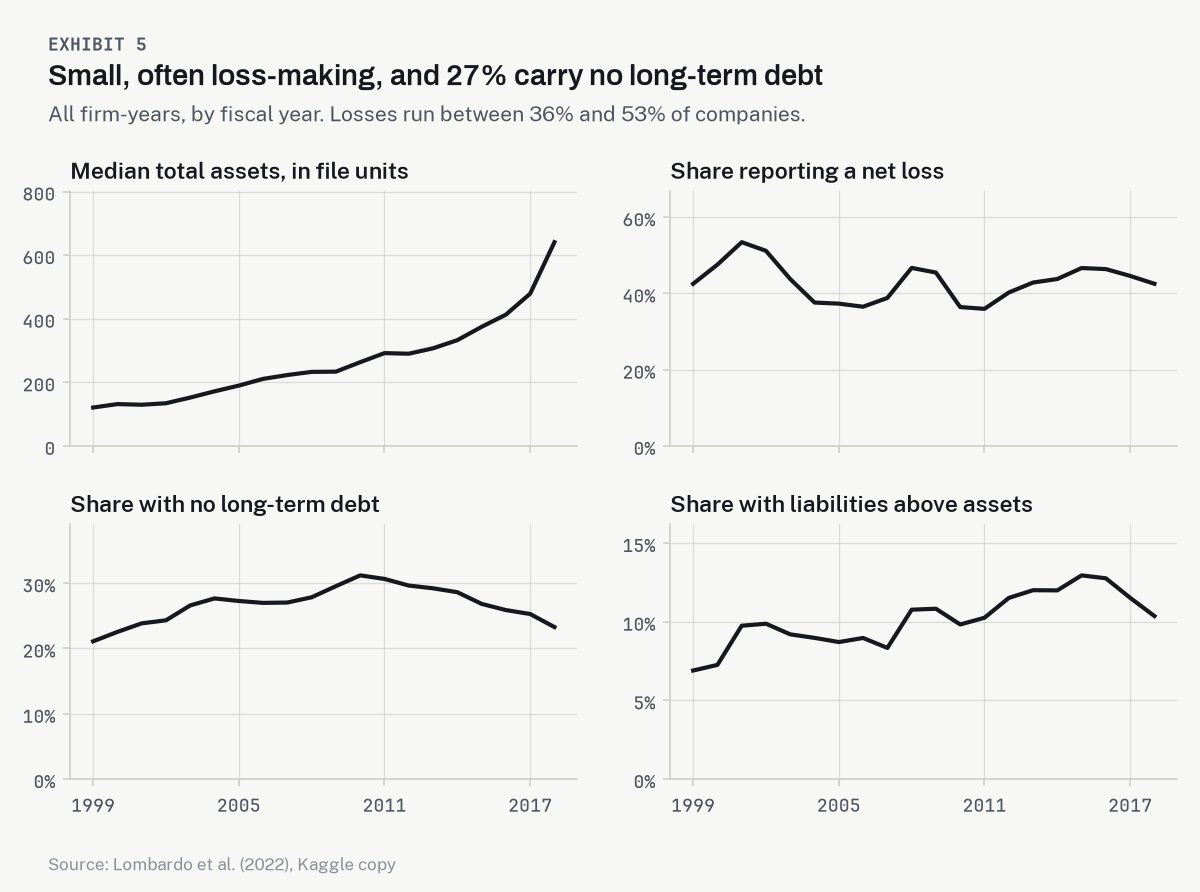

In [17]:
flags = raw.assign(
    net_loss=raw["net_income"] < 0,
    no_lt_debt=raw["total_lt_debt"] == 0,
    negative_equity=raw["total_assets"] < raw["total_liabilities"],
)
profile = flags.groupby("year").agg(
    median_assets=("total_assets", "median"),
    net_loss=("net_loss", "mean"),
    no_lt_debt=("no_lt_debt", "mean"),
    negative_equity=("negative_equity", "mean"),
)

store.put("loss_share", flags["net_loss"].mean())
store.put("loss_low", profile["net_loss"].min())
store.put("loss_high", profile["net_loss"].max())
store.put("no_debt_share", flags["no_lt_debt"].mean())
store.put("negative_equity_share", flags["negative_equity"].mean())
store.put("assets_growth", profile["median_assets"].iloc[-1] / profile["median_assets"].iloc[0])

panels = [
    ("median_assets", "Median total assets, in file units"),
    ("net_loss", "Share reporting a net loss"),
    ("no_lt_debt", "Share with no long-term debt"),
    ("negative_equity", "Share with liabilities above assets"),
]
fig, axes = plt.subplots(2, 2, figsize=(viz.EXHIBIT_WIDTH_IN, 4.6), sharex=True)
for ax, (column, title) in zip(axes.flat, panels):
    ax.plot(profile.index, profile[column], color=viz.INK)
    ax.set_title(title)
    ax.set_ylim(0, profile[column].max() * 1.25)
    if column != "median_assets":
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4, steps=[1, 2, 5, 10]))
        ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xticks(range(first_year, last_year + 1, 6))
viz.exhibit(
    fig,
    f"Small, often loss-making, and {flags.no_lt_debt.mean():.0%} carry no long-term debt",
    f"All firm-years, by fiscal year. Losses run between {profile['net_loss'].min():.0%} and "
    f"{profile['net_loss'].max():.0%} of companies.",
    SOURCE,
)

**Reading.** Exhibit 5 is not a picture of large, steady bond issuers.
A net loss shows in 43% of all firm-years, and no year is below 36%.

Long-term debt is absent in 27% of firm-years, and 10% owe more than they own.

The median company of the last year is 5.3 times the size of the median company of the first.
They are not the same companies.

Q. How is size spread across the firm-years?

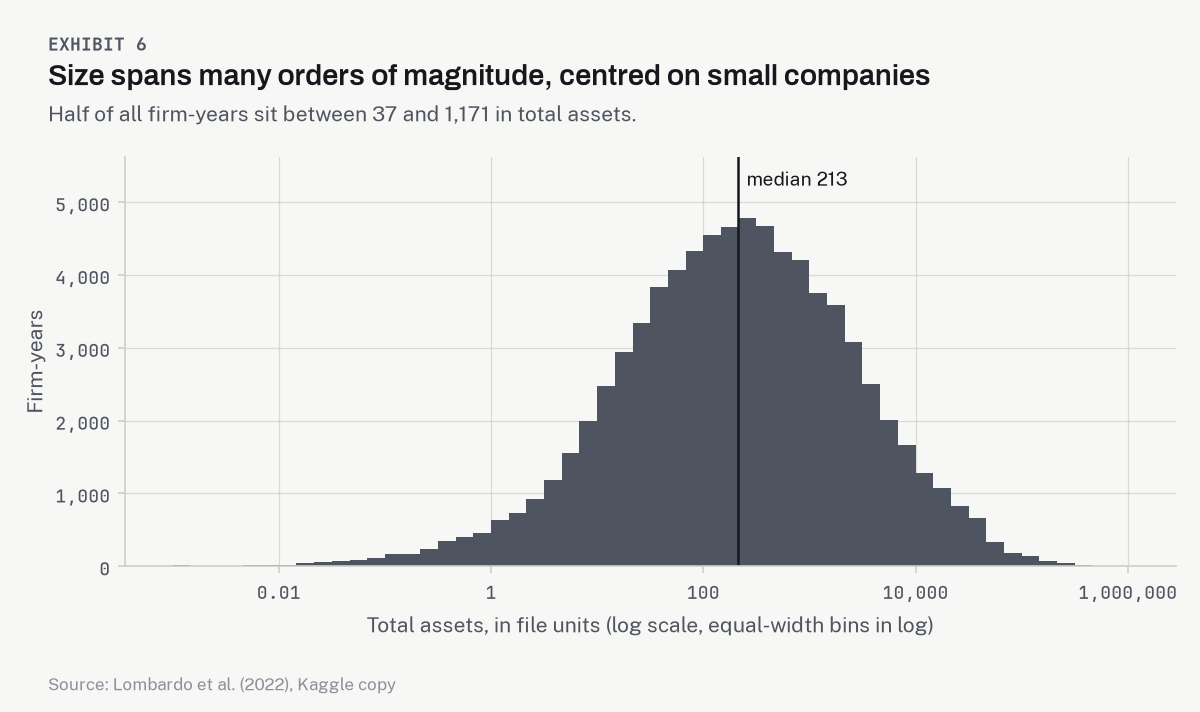

In [18]:
assets = raw["total_assets"]
quartiles = assets.quantile([0.25, 0.5, 0.75])
bins = np.logspace(np.floor(np.log10(assets.min())), np.ceil(np.log10(assets.max())), 55)

store.put("median_assets", quartiles.loc[0.5])
store.put("assets_q1", quartiles.loc[0.25])
store.put("assets_q3", quartiles.loc[0.75])
store.put("assets_span", np.log10(assets.quantile(0.99) / assets.quantile(0.01)))

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.4))
ax.hist(assets, bins=bins, color=viz.SLATE)
viz.log_axis(ax, "x")
ax.set_ylim(top=ax.get_ylim()[1] * 1.12)
ax.axvline(quartiles.loc[0.5], color=viz.INK, linewidth=1.2)
ax.text(
    quartiles.loc[0.5] * 1.2,
    ax.get_ylim()[1] * 0.93,
    f"median {quartiles.loc[0.5]:,.0f}",
    size=9,
)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.set_xlabel("Total assets, in file units (log scale, equal-width bins in log)")
ax.set_ylabel("Firm-years")
viz.exhibit(
    fig,
    "Size spans many orders of magnitude, centred on small companies",
    f"Half of all firm-years sit between {quartiles.loc[0.25]:,.0f} and "
    f"{quartiles.loc[0.75]:,.0f} in total assets.",
    SOURCE,
)

**Reading.** Exhibit 6 puts the bins where the data is: equal steps in the logarithm.
The median firm-year has total assets of 213 in the file's units, and the middle half lies between 37 and 1,171.

Leaving out the smallest and the largest hundredth, the firm-years still span 5.3 orders of magnitude.
A raw amount on that scale says more about size than about health, which is the argument for the ratios of Chapter 3.

Q. Does the industry mix move over the years?

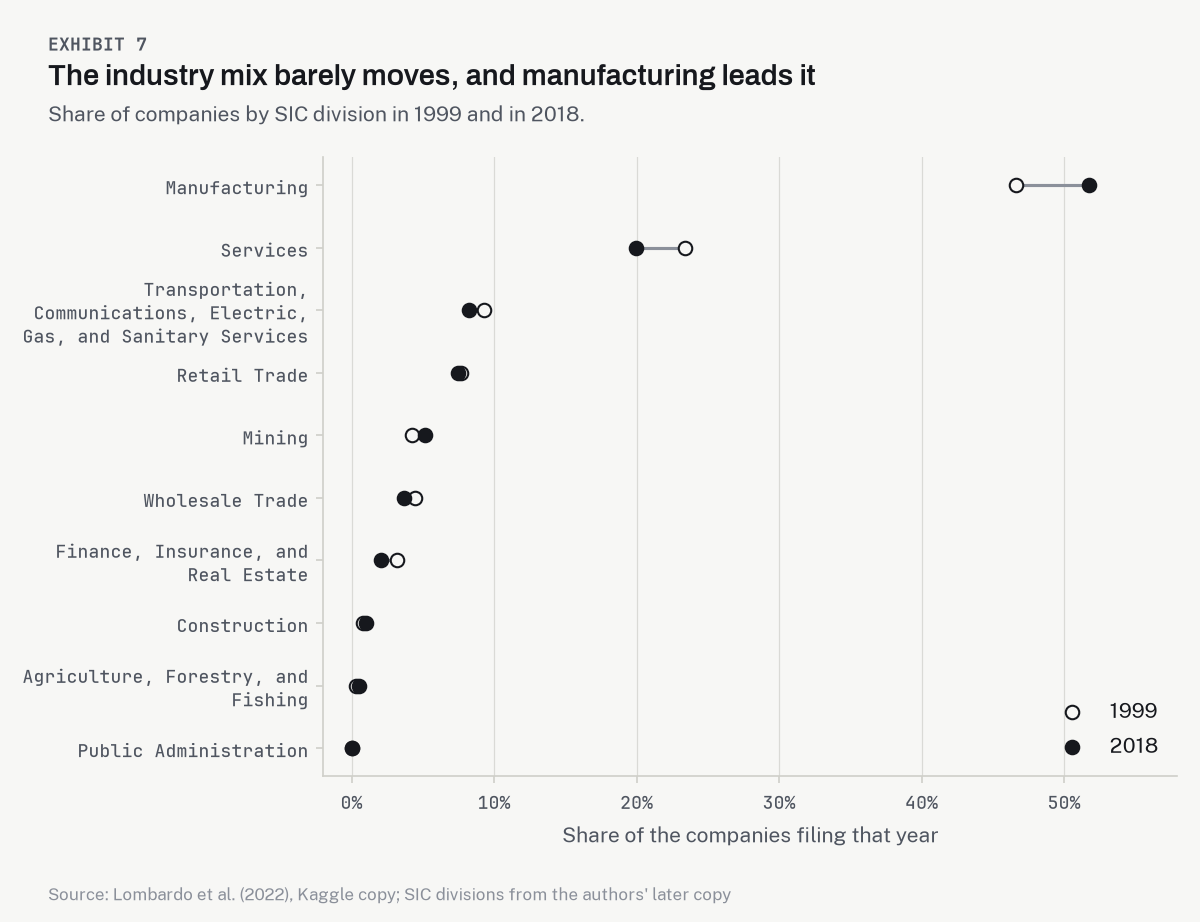

In [19]:
with_industry = raw.join(industry, on="company_name")
mix = pd.crosstab(with_industry["year"], with_industry["division"], normalize="index")
ends = mix.loc[[first_year, last_year]].T.sort_values(last_year)
names = [textwrap.fill(DIVISIONS[letter], 26) for letter in ends.index]
places = range(len(ends))

store.put("manufacturing_first", ends.loc["D", first_year])
store.put("manufacturing_last", ends.loc["D", last_year])

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 4.8))
ax.hlines(places, ends[first_year], ends[last_year], color=viz.MIST, linewidth=1.5)
ax.scatter(ends[first_year], places, s=42, facecolor=viz.SHEET, edgecolor=viz.INK, zorder=3,
           label=str(first_year))  # fmt: skip
ax.scatter(ends[last_year], places, s=42, color=viz.INK, zorder=3, label=str(last_year))
ax.set_yticks(places, names)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(-0.02, ends.to_numpy().max() * 1.12)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of the companies filing that year")
ax.legend(loc="lower right")
viz.exhibit(
    fig,
    "The industry mix barely moves, and manufacturing leads it",
    f"Share of companies by SIC division in {first_year} and in {last_year}.",
    f"{SOURCE}; SIC divisions from the authors' later copy",
)

**Reading.** In Exhibit 7 no division moves far: manufacturing goes from 47% of the companies to 52%.
A model trained on the early years meets much the same industries in the late ones.

Whether it meets the same balance sheets is a different question, and Chapter 3 takes it up.

**Next, whether the accounts agree with each other.**

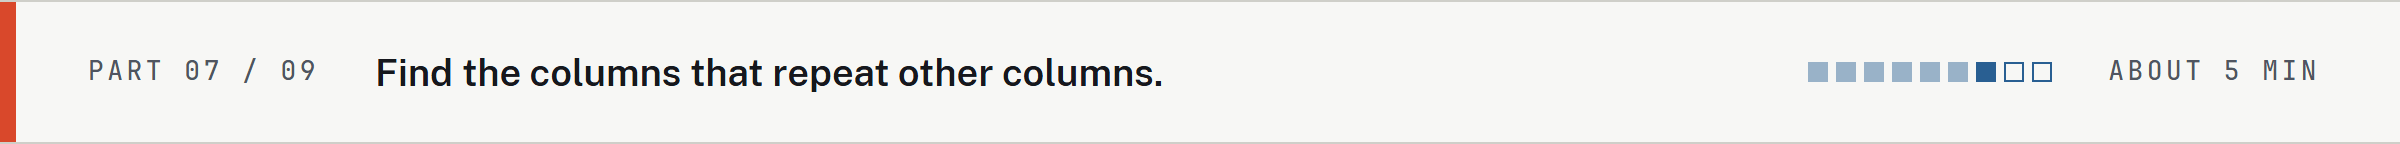

# Do the Numbers Add Up

Accounts obey arithmetic.
Gross profit is sales less the cost of goods sold, whoever reports it.

A column that is arithmetic on other columns carries no new information.

Q. Which columns can be rebuilt from the others?

In [20]:
full = pd.read_csv(DATA_PATH).rename(columns=COLUMN_MAP)  # all 18 columns, as they sit on disk
items = list(COLUMN_MAP.values())
identities = {
    "total_revenue = net_sales": (full["total_revenue"], full["net_sales"]),
    "gross_profit = net_sales - cogs": (full["gross_profit"], full["net_sales"] - full["cogs"]),
    "ebit = ebitda - depreciation_amort": (
        full["ebit"],
        full["ebitda"] - full["depreciation_amort"],
    ),
    "total_operating_expenses = net_sales - ebitda": (
        full["total_operating_expenses"],
        full["net_sales"] - full["ebitda"],
    ),
}
# The file stores rounded values, so the two sides can differ by rounding alone.
agrees = pd.DataFrame(
    {name: np.isclose(left, right, atol=0.0015) for name, (left, right) in identities.items()}
)
holds = pd.DataFrame({"share of rows": agrees.mean(), "rows that break it": (~agrees).sum()})

store.put("items", len(items))
store.put("identities", len(identities))
store.put("identity_min", holds["share of rows"].min())
store.put("identity_breaks", int(holds["rows that break it"].sum()))

holds.assign(**{"share of rows": holds["share of rows"].map("{:.4%}".format)})

,share of rows,rows that break it
total_revenue = net_sales,100.0000%,0
gross_profit = net_sales - cogs,99.9975%,2
ebit = ebitda - depreciation_amort,99.9962%,3
total_operating_expenses = net_sales - ebitda,99.9949%,4


**Reading.** Each of the 4 identities holds on at least 99.99% of rows, to within rounding, and only 9 rows break one.
`total_revenue` is `net_sales` under a second name, which is why `load_raw` drops it.

**Predict 4.** The file has 18 accounting columns.
How many carry information the others do not?

Q. How many independent columns are there?

Standardise every column, then take the **singular values** of the table.
Each one measures how much the data varies along one direction.

A direction with no variation at all means some column is a combination of the others.

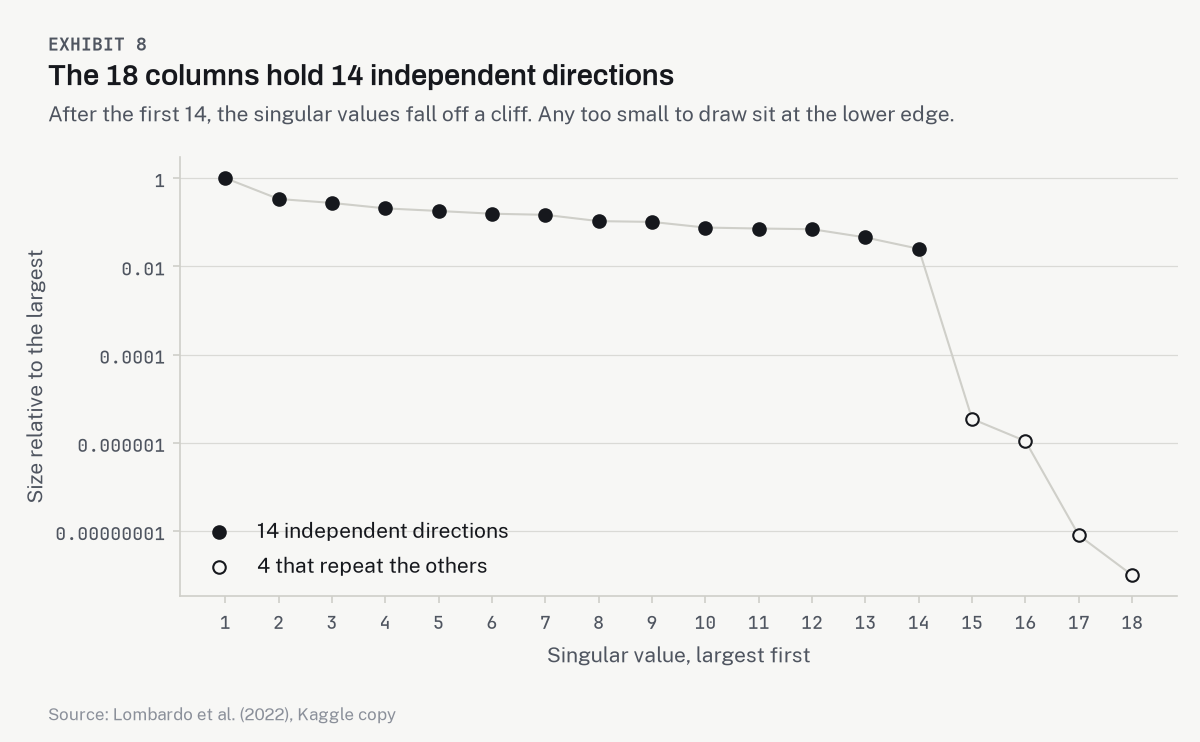

In [21]:
standardised = (full[items] - full[items].mean()) / full[items].std()
singular = np.linalg.svd(standardised.to_numpy(), compute_uv=False)
relative = singular / singular[0]
independent = int((relative > 1e-5).sum())
FLOOR = 1e-9  # the chart's lower edge; smaller values are drawn on it

store.put("independent", independent)
store.put("dependent", len(items) - independent)
store.put("default_rank", int(np.linalg.matrix_rank(standardised.to_numpy())))
store.put("cliff", relative[independent - 1] / relative[independent])

order = np.arange(1, len(items) + 1)
kept = order <= independent
fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.6))
ax.plot(order, np.maximum(relative, FLOOR), color=viz.RULE, linewidth=1, zorder=1)
ax.scatter(order[kept], relative[kept], s=36, color=viz.INK, zorder=3,
           label=f"{independent} independent directions")  # fmt: skip
ax.scatter(order[~kept], np.maximum(relative[~kept], FLOOR), s=36, facecolor=viz.SHEET,
           edgecolor=viz.INK, zorder=3, label=f"{len(items) - independent} that repeat the others")  # fmt: skip
viz.log_axis(ax, "y")
ax.set_ylim(FLOOR / 3, 3)
ax.set_xticks(order)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Singular value, largest first")
ax.set_ylabel("Size relative to the largest")
ax.legend(loc="lower left")
viz.exhibit(
    fig,
    f"The {len(items)} columns hold {independent} independent directions",
    f"After the first {independent}, the singular values fall off a cliff. "
    "Any too small to draw sit at the lower edge.",
    SOURCE,
)

**Reading.** Exhibit 8 has a cliff after the first 14 values: the next one is 7,175 times smaller.
The 4 values below the cliff are the 4 identities, seen from the other side.

They are not exactly zero, because the file stores rounded values.
That rounding is enough to fool `np.linalg.matrix_rank`, which reports 17 here: it looks for exact dependence and finds only the copy.

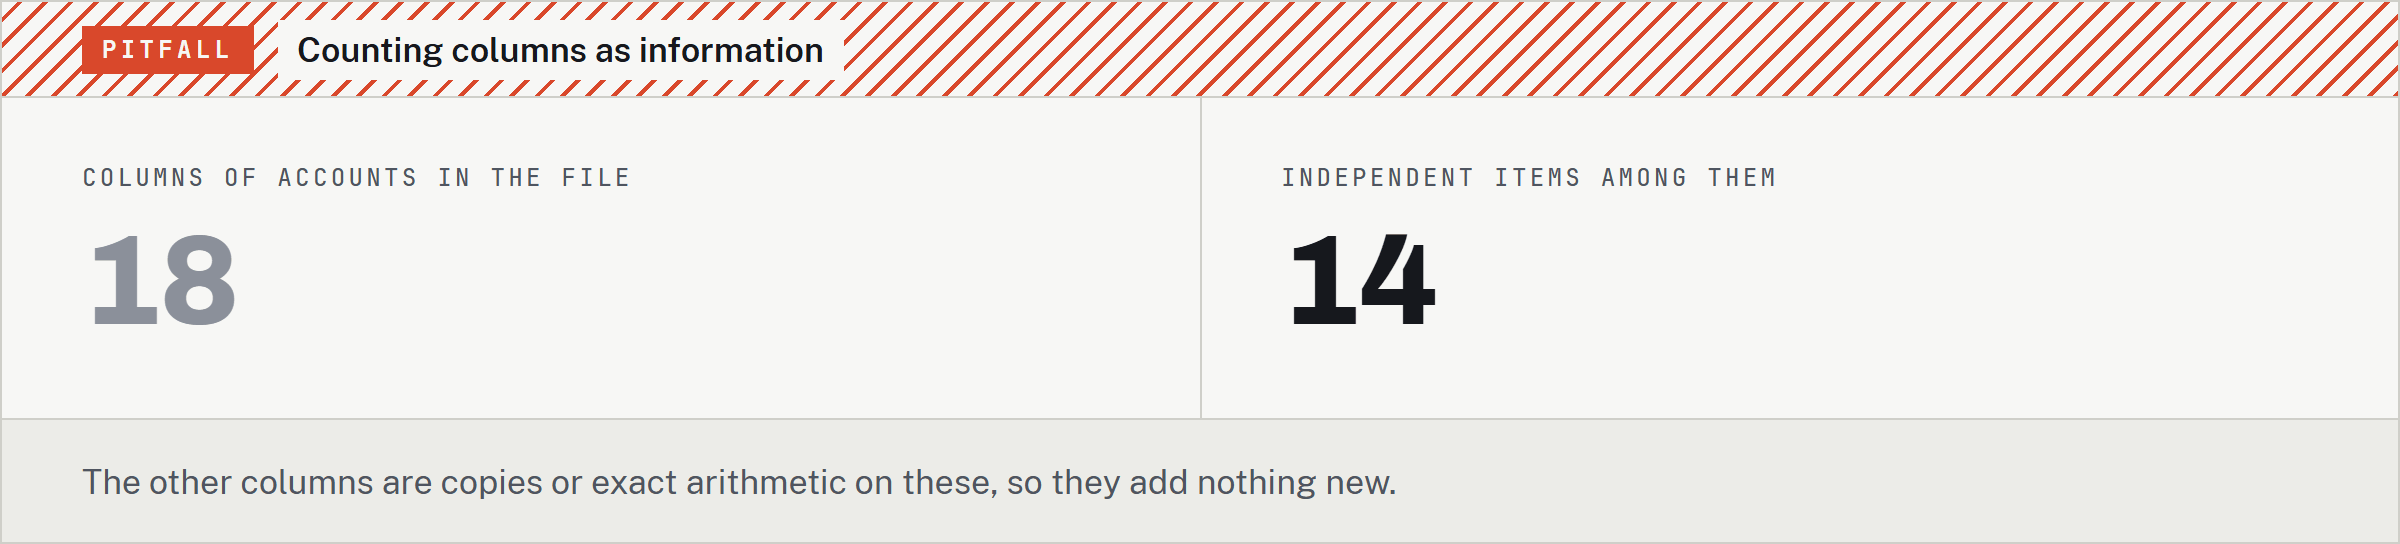

Q. Do any rows hold values that look wrong?

In [22]:
oddities = pd.Series(
    {
        "missing values": int(full[items].isna().sum().sum()),
        "repeated company and year": int(full.duplicated(["company_name", "year"]).sum()),
        "negative net sales": int((full["net_sales"] < 0).sum()),
        "negative cost of goods sold": int((full["cogs"] < 0).sum()),
        "current assets above total assets": int(
            (full["current_assets"] > full["total_assets"] + 0.0015).sum()
        ),
        "current liabilities above total liabilities": int(
            (full["total_current_liabilities"] > full["total_liabilities"] + 0.0015).sum()
        ),
    },
    name="rows",
)

store.put("odd_rows", int(oddities.sum()))
store.put("negative_sales", oddities.loc["negative net sales"])

oddities.to_frame()

,rows
missing values,0
repeated company and year,0
negative net sales,13
negative cost of goods sold,6
current assets above total assets,1
current liabilities above total liabilities,2


**Reading.** The file has no missing value and no repeated firm-year.
It does hold a few rows that look wrong, such as the 13 with negative net sales.

They are 22 rows in 78,682.
This casebook leaves them in and says so, since dropping rows by hand is a choice a reader could not see.

**Check.** `gross_profit` is exact arithmetic on two other columns. Does it help a model to have all three?

<details>
<summary>Show the answer</summary>

It adds no information, and it can do harm.
A linear model cannot tell the three apart, so its coefficients on them are arbitrary.

A tree model splits its importance across them, which makes each look weaker than it is.
The model's input should be the independent items, or ratios built from them.

</details>

**Next, how to look at numbers that can be negative.**

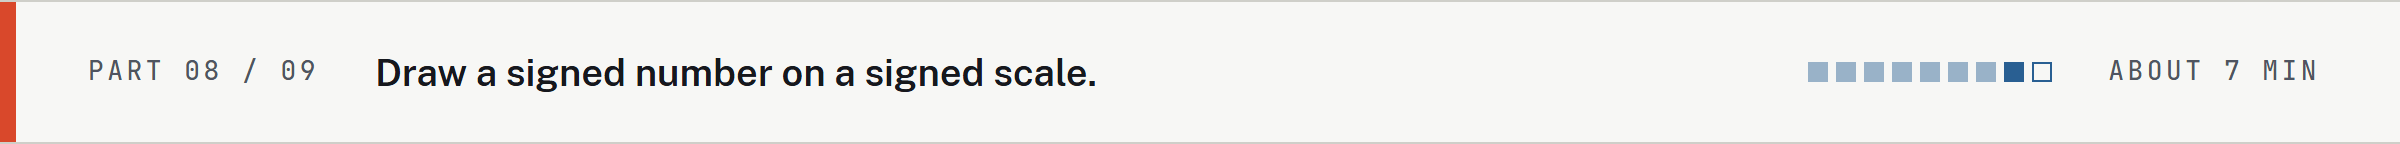

# Signed Numbers Need a Signed Scale

Company accounts are skewed: a few giants and many small companies.
A log axis is the usual answer.

But net income can be negative, and a logarithm cannot take a negative number.
A common workaround is to add a constant so that everything is positive, then use a log axis.

Q. What does that workaround show for net income?

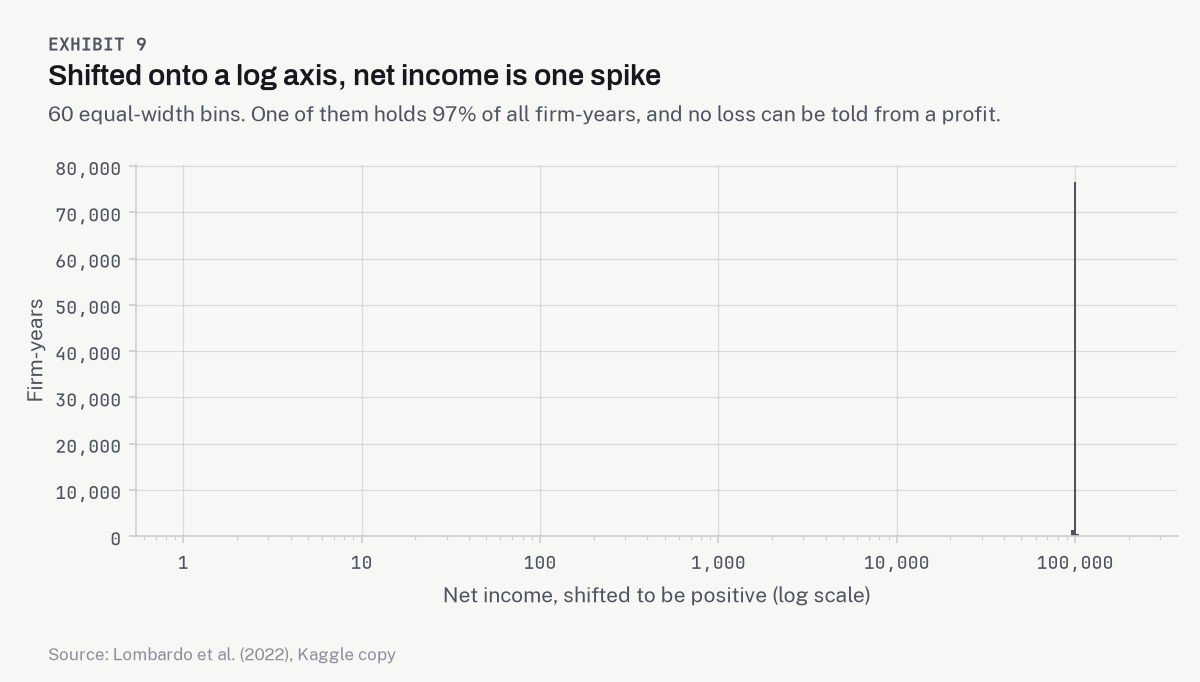

In [23]:
BARS = 60
income = raw["net_income"]
shifted = income - income.min() + 1

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.2))
naive_counts, _, _ = ax.hist(shifted, bins=BARS, color=viz.SLATE)
viz.log_axis(ax, "x")
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.set_xlabel("Net income, shifted to be positive (log scale)")
ax.set_ylabel("Firm-years")

store.put("naive_tallest", naive_counts.max() / len(income))
store.put("income_negative", (income < 0).mean())

viz.exhibit(
    fig,
    "Shifted onto a log axis, net income is one spike",
    f"{BARS} equal-width bins. One of them holds {naive_counts.max() / len(income):.0%} of all "
    "firm-years, and no loss can be told from a profit.",
    SOURCE,
)

**Reading.** Exhibit 9 shows almost nothing: one bar holds 97% of the firm-years.
The shift is as large as the largest loss in the file, so every ordinary profit and loss lands at nearly the same place.

Q. What does a scale built for signed numbers show?

A **symmetric-log** axis is linear close to zero and logarithmic beyond it, on both sides.
`viz.symlog_axis` sets one.

The bins follow the same idea, so every bar is about as wide on the page as its neighbours.

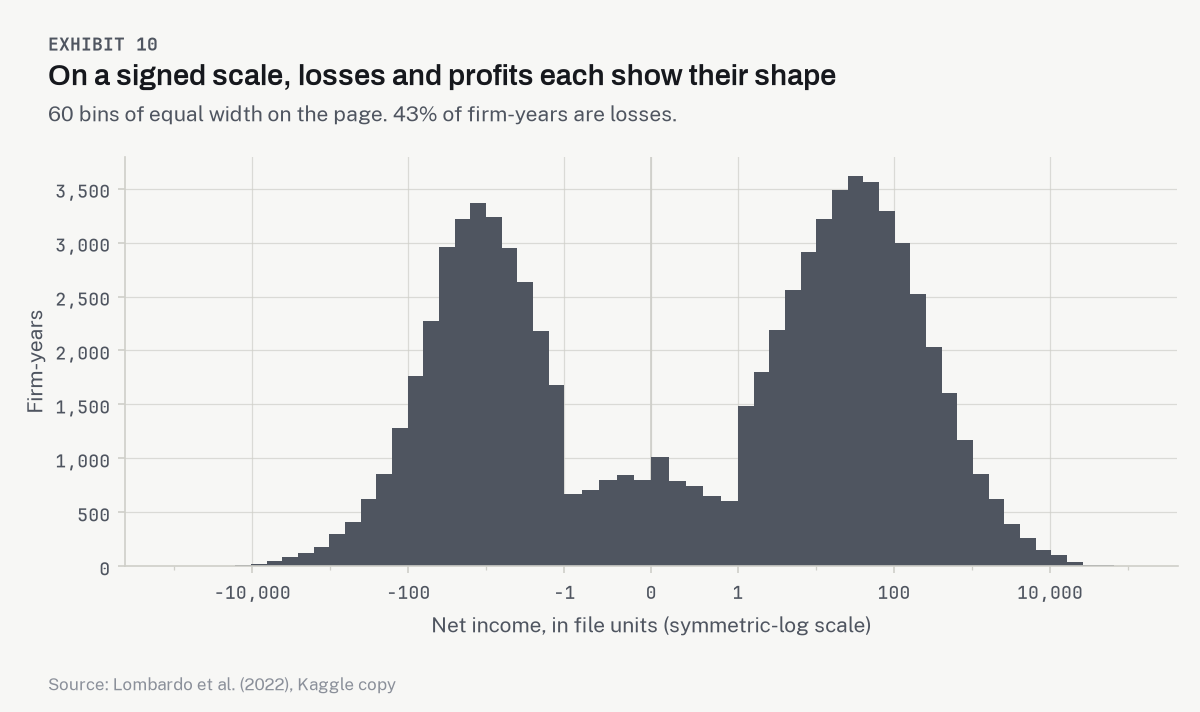

In [24]:
PER_DECADE = 5  # bars to a decade; the linear stretch from zero to one is as wide as a decade
outer = (BARS - 2 * PER_DECADE) // 2
steps = np.logspace(0, np.log10(income.abs().max()), outer + 1)
inner = np.linspace(-1, 1, 2 * PER_DECADE + 1)[1:-1]
signed_bins = np.concatenate([-steps[::-1], inner, steps])

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.4))
honest_counts, _, _ = ax.hist(income, bins=signed_bins, color=viz.SLATE)
viz.symlog_axis(ax, "x", linthresh=1.0)
ax.set_xticks([-1e4, -1e2, -1, 0, 1, 1e2, 1e4])
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.set_xlabel("Net income, in file units (symmetric-log scale)")
ax.set_ylabel("Firm-years")

store.put("honest_tallest", honest_counts.max() / len(income))
store.put("bars", len(signed_bins) - 1)

viz.exhibit(
    fig,
    "On a signed scale, losses and profits each show their shape",
    f"{len(signed_bins) - 1} bins of equal width on the page. "
    f"{(income < 0).mean():.0%} of firm-years are losses.",
    SOURCE,
)

**Reading.** Exhibit 10 is the same column, with losses on the left and profits on the right.
Losses are 43% of firm-years, and the tallest bar now holds 5% of the data.

The step on each side of zero is where the axis changes from linear to logarithmic.

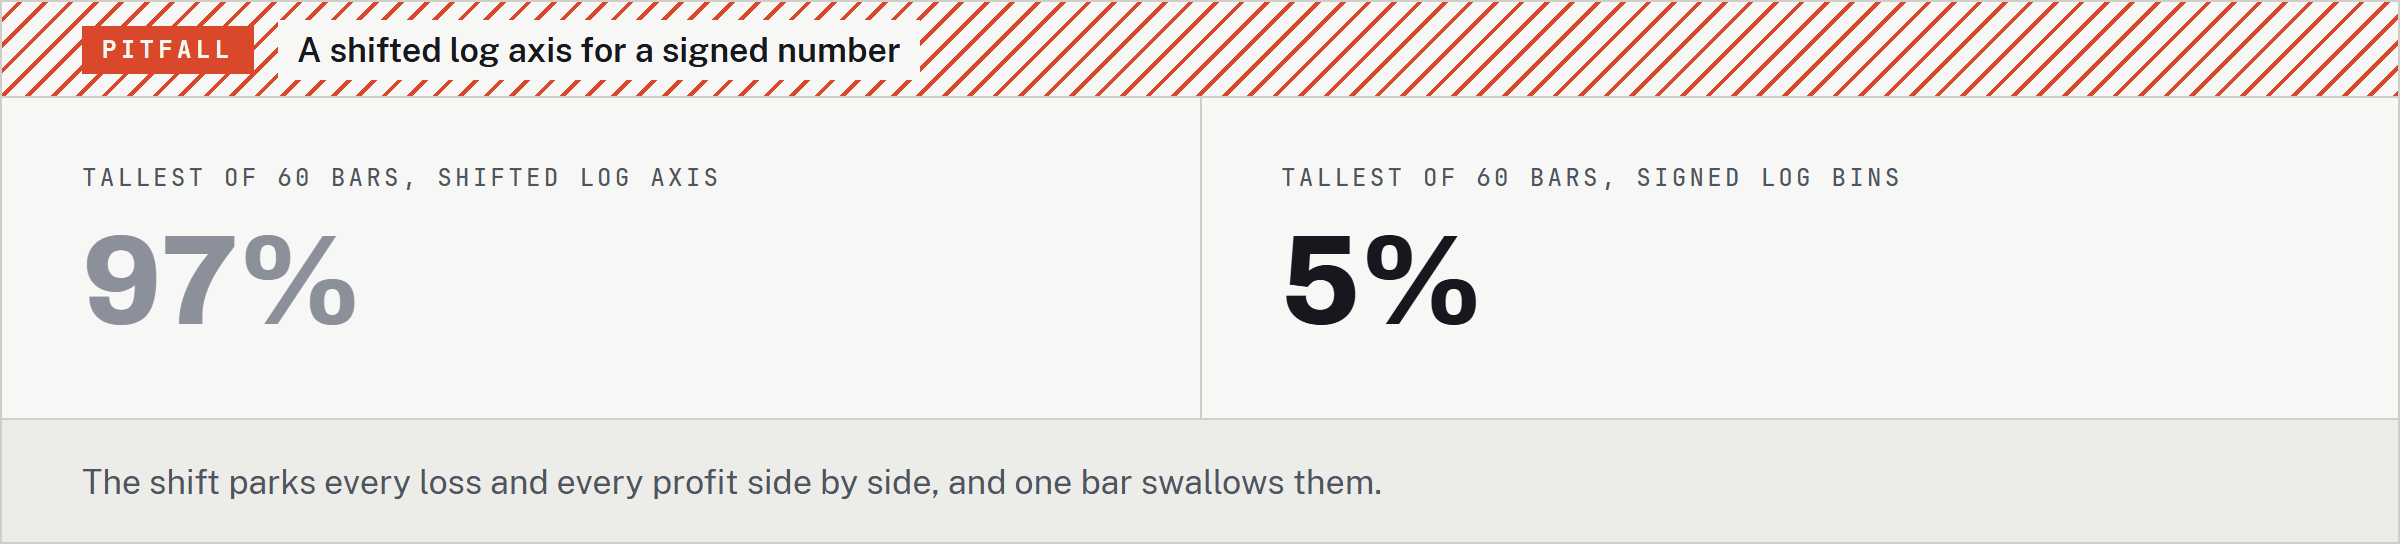

Q. What do all the accounts look like on that scale?

A **letter-value plot** is a box plot with more boxes.
The widest box holds the middle half of the data.

Each narrower box reaches half-way again into what is left of each tail.

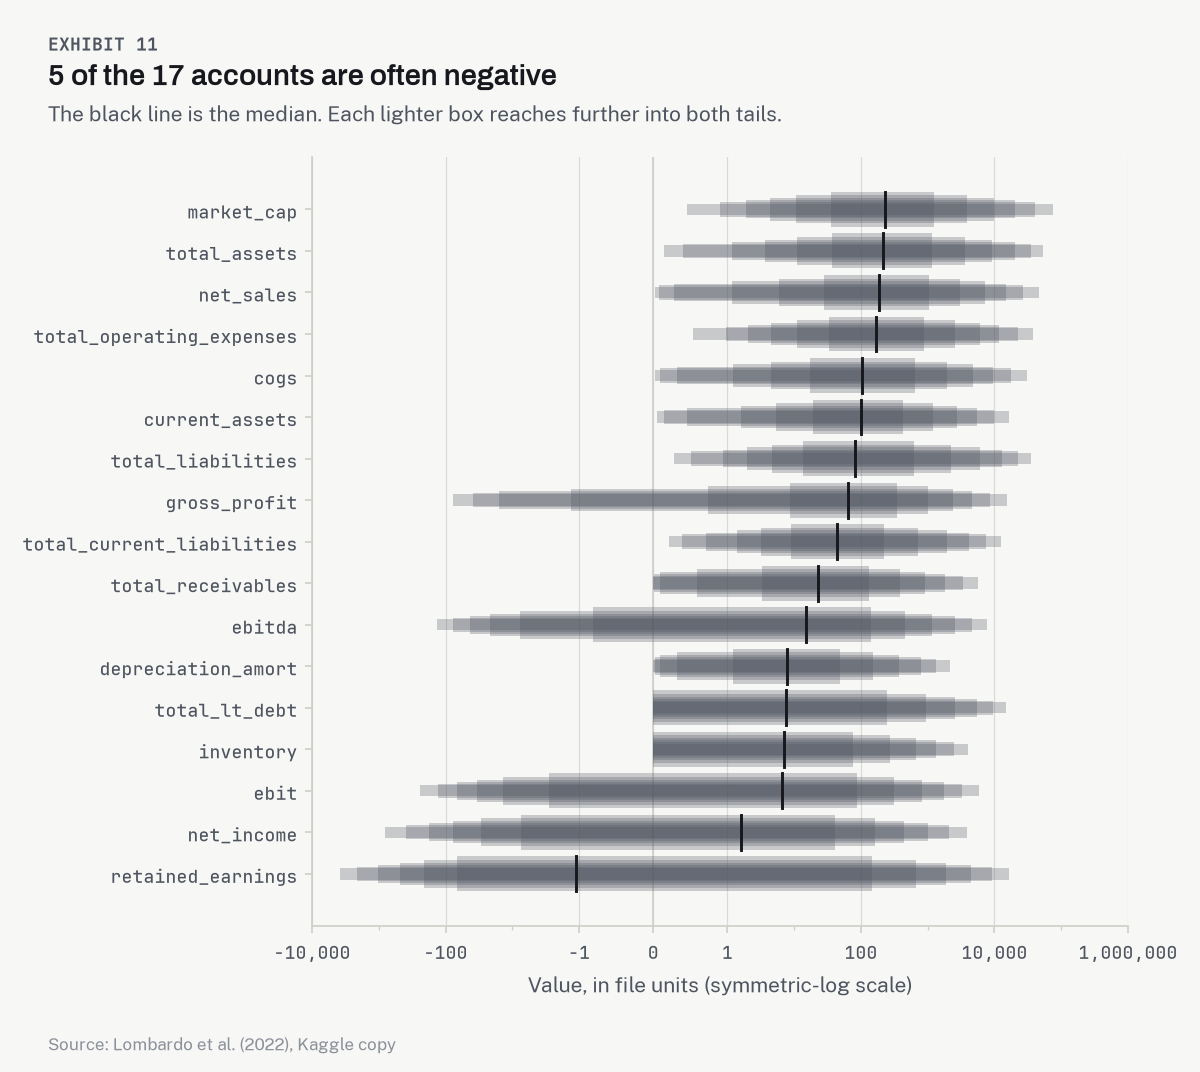

In [25]:
def letter_values(values: pd.Series, depth: int = 6) -> list[tuple[float, float]]:
    """Nested quantile ranges: the middle half, then the middle three quarters, and so on."""
    tails = [2.0 ** -(level + 1) for level in range(1, depth + 1)]
    return [(values.quantile(tail), values.quantile(1 - tail)) for tail in tails]


ordered = raw[RAW_ITEMS].median().sort_values().index
fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 5.8))
for row, item in enumerate(ordered):
    for level, (low, high) in enumerate(letter_values(raw[item])):
        # Boxes overlap, so the middle of each distribution is drawn darkest.
        ax.barh(row, high - low, left=low, height=0.84 * 0.8**level, color=viz.SLATE, alpha=0.28)
    ax.plot([raw[item].median()] * 2, [row - 0.42, row + 0.42], color=viz.INK, linewidth=1.4)
viz.symlog_axis(ax, "x", linthresh=1.0)
ax.set_xticks([-1e4, -1e2, -1, 0, 1, 1e2, 1e4, 1e6])
ax.set_yticks(range(len(ordered)), ordered)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Value, in file units (symmetric-log scale)")

OFTEN = 0.01  # an account is called signed when more than this share of its rows is negative
signed = [item for item in RAW_ITEMS if (raw[item] < 0).mean() > OFTEN]
store.put("often", OFTEN)
store.put("signed_items", len(signed))

viz.exhibit(
    fig,
    f"{len(signed)} of the {len(RAW_ITEMS)} accounts are often negative",
    "The black line is the median. Each lighter box reaches further into both tails.",
    SOURCE,
)

**Reading.** Exhibit 11 reads from the bottom up, by median.
The earnings lines, gross profit, and retained earnings are negative in more than 1% of rows: 5 of the 17 accounts.

The rest pile up at or above zero, and some, like inventory and long-term debt, are exactly zero for many companies.
Every one of them spans several orders of magnitude.

**Check.** Why not take the logarithm of the absolute value and keep the sign in a second column?

<details>
<summary>Show the answer</summary>

That folds the number line at zero, so a small loss and a small profit land on the same value.
It also sends values near zero toward minus infinity.

The symmetric-log scale keeps the order of the numbers and stays finite at zero.

</details>

**Next, what is not in the file at all.**

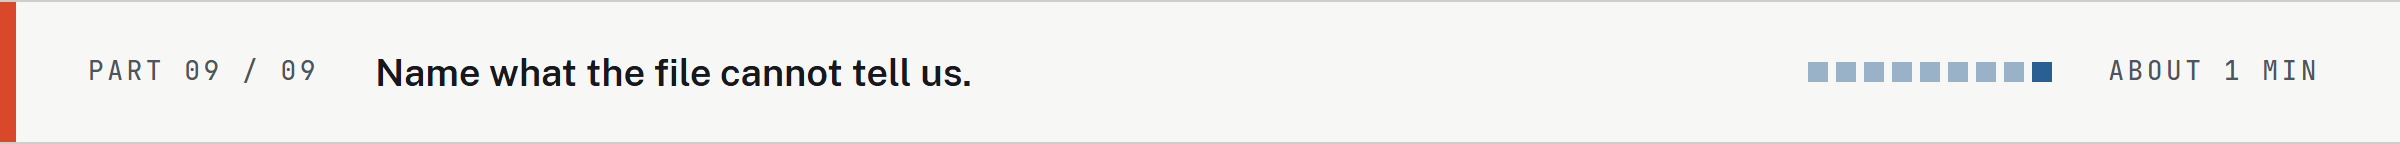

# What the File Cannot Tell Us

A dataset is defined as much by what it leaves out.
Each missing field closes off a kind of analysis, and it is better to know that now.

| Not in the file | What that rules out |
| --- | --- |
| Cash | The quick test of who can pay next quarter's bills |
| Interest expense | Interest coverage |
| Short-term debt | Total debt, and so leverage as a lender measures it |
| The date of the bankruptcy filing | Measuring how far ahead a warning came, in months |
| The reason a company leaves | Telling a merger from a delisting, or either from a quiet failure |
| Company names | Joining ratings, prices, or anything else from outside |
| Units | Quoting an amount |
| Accounts before the first year | The age of the companies already listed when the file begins |

None of this stops the work.
It sets the terms: the casebook predicts a bankruptcy filing from annual accounts, for a universe of mostly small companies, with the event dated to the year.

**The next chapter takes the flag and asks what it means for a company to fail, and when.**

# Findings

1. The file holds 78,682 firm-years from 8,971 companies, and the number filing falls by 49% over 20 years (Exhibit 1).
2. More companies leave than join, and only 10% of those that leave are failures (Exhibit 2).
3. Of all the companies, 59% are already present in the first year, so their earlier history is cut off (Exhibit 3).
4. Histories are short: the median is 7 years, and 13% of companies are present throughout (Exhibit 4).
5. The universe is small and often loss-making: 43% of firm-years show a net loss and 27% carry no long-term debt (Exhibit 5, Exhibit 6).
6. The industry mix is stable: manufacturing is 47% of the companies in the first year and 52% in the last (Exhibit 7).
7. The 18 accounting columns hold 14 independent items (Exhibit 8).
8. Losses are 43% of firm-years, and only a signed scale shows them (Exhibit 9, Exhibit 10, Exhibit 11).

# Your Turn

Three extensions, each with a hint folded under it.

**1. The longest break.** Find the company with the longest gap in its filings and list the years it did file.

<details>
<summary>Hint</summary>

Sort `spans` by `n_gap_years`, take the top company, and filter `raw` to it.

</details>

**2. Lifelines of the failed.** Redraw Exhibit 3 for failed companies only. Do they join and leave like the rest?

<details>
<summary>Hint</summary>

Sample from `events.loc[events["event"] == "failed"]` in place of `events`.

</details>

**3. Inside manufacturing.** Which major groups make up division D, and which is the largest?

<details>
<summary>Hint</summary>

Filter `industry` to `division == "D"` and count `major_group`.

</details>

[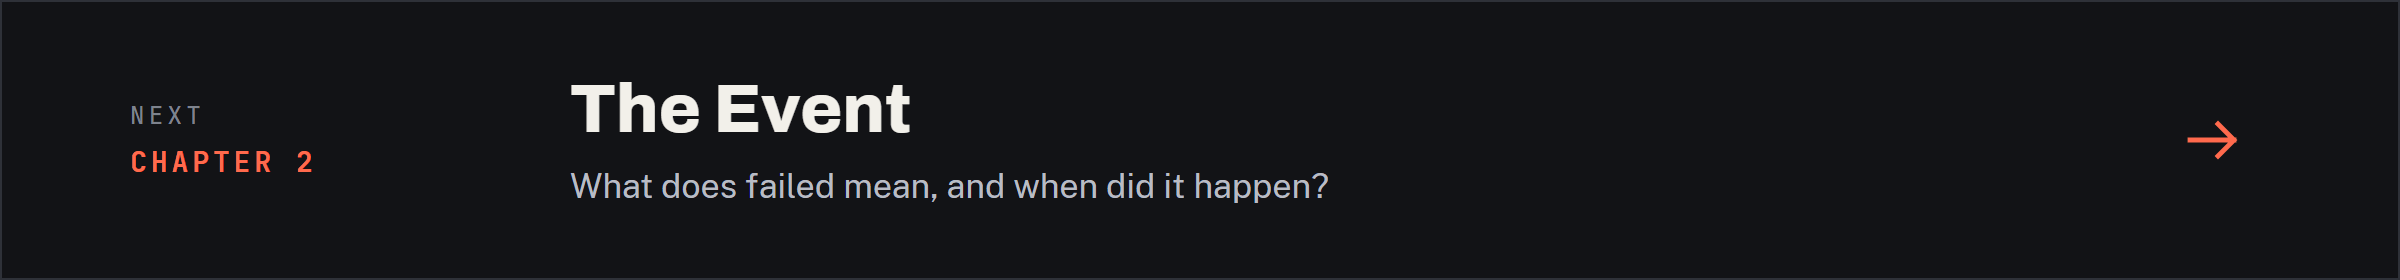](02_the_event.ipynb)